# Cross-Modal Incongruity Modelling for Multimodal Sarcasm Detection (CM-GAN)

**COMP6001 Capstone — Zhipeng Zhang**

This notebook is the executable form of the project: it downloads the MMSD data, builds the
dataset figures, extracts the frozen encoder features, trains CM-GAN and the six comparison
configurations, and reproduces every table and figure in the report.

**Before running:** `Runtime → Change runtime type → GPU` (a T4 is enough), then `Runtime → Run all`.

**Expected runtime on a Colab T4:** about 2 hours end to end (the download and the feature
extraction dominate; the 36 training runs take roughly an hour together). A `QUICK MODE` cell is
provided below if you only want to see the pipeline work — it finishes in ~15 minutes on a subset
of epochs and folds, so its numbers will differ from the report.

**Headline results reproduced by the full run** (macro-F1 on the official 2,409-example test split,
mean over 5 folds):

| Model | Macro-F1 |
|---|---|
| CM-GAN (full) | 0.8173 ± 0.0038 |
| CM-GAN without cross-attention | 0.8121 ± 0.0053 |
| CM-GAN without gate | 0.8107 ± 0.0036 |
| Early fusion (concat) | 0.7949 ± 0.0030 |
| Late fusion (decision) | 0.7946 ± 0.0029 |
| BERT text-only | 0.7841 ± 0.0016 |
| ResNet-50 vision-only | 0.7093 ± 0.0037 |


## 1. Environment

In [1]:
!nvidia-smi -L
!pip install -q torch torchvision pyarrow transformers scikit-learn scipy matplotlib seaborn tqdm

import os
os.makedirs('src', exist_ok=True)
print('ready')

GPU 0: NVIDIA GeForce RTX 3080 Ti (UUID: GPU-2c9aed67-89c5-a547-172f-46e2e05b8558)


ready



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


## 2. Source code

Each module of `src/` is written to disk here, so the notebook and the repository stay identical.
Nothing is hidden in a package that has to be downloaded separately.

In [2]:
%%writefile src/config.py
"""Project-wide paths and hyper-parameters.

Every script resolves paths from this module so the whole pipeline can be
moved to another machine / Colab by editing ROOT only.
"""
from pathlib import Path

ROOT = Path(__file__).resolve().parents[1]

DATA = ROOT / "data"
RAW = DATA / "raw"
IMAGES = DATA / "images"
MANIFESTS = DATA / "manifests"
FEATURES = DATA / "features"
HF_CACHE = DATA / "hf_cache"

OUT = ROOT / "outputs"
FIG = OUT / "figures"
METRICS = OUT / "metrics"
CKPT = OUT / "checkpoints"
LOGS = OUT / "logs"

for _p in (DATA, RAW, IMAGES, MANIFESTS, FEATURES, OUT, FIG, METRICS, CKPT, LOGS):
    _p.mkdir(parents=True, exist_ok=True)

# ---------------------------------------------------------------- dataset
HF_REPO = "coderchen01/MMSD2.0"
HF_SUBFOLDER = "mmsd-v1"
HF_BASE = f"https://huggingface.co/datasets/{HF_REPO}/resolve/main/{HF_SUBFOLDER}"
SPLIT_FILES = {
    "train": [f"train-0000{i}-of-00004.parquet" for i in range(4)],
    "validation": ["validation-00000-of-00001.parquet"],
    "test": ["test-00000-of-00001.parquet"],
}

# ------------------------------------------------------------- encoders
TEXT_MODEL = "bert-base-uncased"
VISION_ARCH = "resnet50"
IMG_SIZE = 224
TEXT_MAX_LEN = 48
VIS_TOKENS = 49          # 7 x 7 grid after layer4 on 224x224 input
VIS_DIM = 2048           # ResNet-50 layer4 channels
TXT_DIM = 768            # BERT-base hidden size

# --------------------------------------------------------------- model
PROJ_DIM = 256
N_HEADS = 4
DROPOUT = 0.2

# ------------------------------------------------------------ training
SEED = 42
N_FOLDS = 5
EPOCHS = 10
BATCH_SIZE = 128
LR = 3e-4
WEIGHT_DECAY = 0.01
WARMUP_FRAC = 0.10
GRAD_CLIP = 1.0
AMP = True

MODELS = [
    "cmgan",
    "cmgan_nogate",
    "cmgan_nocross",
    "text_only",
    "vision_only",
    "early_fusion",
    "late_fusion",
]


Overwriting src/config.py


In [3]:
%%writefile src/utils.py
"""Shared helpers: seeding, JSON I/O, logging, metrics."""
from __future__ import annotations

import json
import logging
import random
import sys
from pathlib import Path

import numpy as np
import torch
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)


def set_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def get_logger(name: str, logfile: Path | None = None) -> logging.Logger:
    logger = logging.getLogger(name)
    logger.setLevel(logging.INFO)
    logger.handlers.clear()
    fmt = logging.Formatter("[%(asctime)s] %(message)s", datefmt="%H:%M:%S")

    sh = logging.StreamHandler(sys.stdout)
    sh.setFormatter(fmt)
    logger.addHandler(sh)

    if logfile is not None:
        logfile.parent.mkdir(parents=True, exist_ok=True)
        fh = logging.FileHandler(logfile, mode="a", encoding="utf-8")
        fh.setFormatter(fmt)
        logger.addHandler(fh)

    logger.propagate = False
    return logger


def save_json(obj, path: Path) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    with open(path, "w", encoding="utf-8") as f:
        json.dump(obj, f, indent=2, ensure_ascii=False)


def load_json(path: Path):
    with open(path, "r", encoding="utf-8") as f:
        return json.load(f)


def compute_metrics(y_true, y_prob, threshold: float = 0.5) -> dict:
    """Six complementary metrics (the proposal promises all of them).

    Macro-F1 is the headline number because MMSD is not perfectly balanced.
    """
    y_true = np.asarray(y_true).astype(int)
    y_prob = np.asarray(y_prob, dtype=float)
    y_pred = (y_prob >= threshold).astype(int)

    out = {
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "precision": float(precision_score(y_true, y_pred, zero_division=0)),
        "recall": float(recall_score(y_true, y_pred, zero_division=0)),
        "f1_binary": float(f1_score(y_true, y_pred, zero_division=0)),
        "f1_macro": float(f1_score(y_true, y_pred, average="macro", zero_division=0)),
    }
    try:
        out["roc_auc"] = float(roc_auc_score(y_true, y_prob))
    except ValueError:
        out["roc_auc"] = float("nan")
    return out


def count_params(model: torch.nn.Module) -> int:
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


Overwriting src/utils.py


In [4]:
%%writefile src/data_prep.py
"""Stage 1 - turn the HuggingFace MMSD parquet shards into a local dataset.

Downloads the `mmsd-v1` config of `coderchen01/MMSD2.0` (the original
Cai, Cai & Wan 2019 split: 19,816 / 2,410 / 2,409), decodes the inline
image bytes into JPEG files, and writes one manifest CSV per split with
per-image statistics that the EDA stage reuses.

Run:
    python -m src.data_prep            # download + decode (all splits)
    python -m src.data_prep --skip-download
"""
from __future__ import annotations

import argparse
import csv
import io
import urllib.request
from pathlib import Path

import numpy as np
from PIL import Image

try:  # package imports when run as `python -m src.data_prep`
    from .config import HF_BASE, IMAGES, LOGS, MANIFESTS, RAW, SPLIT_FILES
    from .utils import get_logger, save_json
except ImportError:  # direct script run
    import sys

    sys.path.append(str(Path(__file__).resolve().parents[1]))
    from src.config import HF_BASE, IMAGES, LOGS, MANIFESTS, RAW, SPLIT_FILES
    from src.utils import get_logger, save_json

log = get_logger("data_prep", LOGS / "data_prep.log")

CSV_FIELDS = [
    "idx", "id", "split", "label", "text", "text_len",
    "img_path", "img_w", "img_h", "img_bytes",
    "brightness", "contrast", "colorfulness",
]


# ------------------------------------------------------------------ download
def download(url: str, dest: Path, retries: int = 3) -> Path:
    """Download with a .part file so an interrupted run can resume."""
    dest.parent.mkdir(parents=True, exist_ok=True)
    if dest.exists() and dest.stat().st_size > 0:
        log.info("skip (exists) %s", dest.name)
        return dest

    part = dest.with_suffix(dest.suffix + ".part")
    for attempt in range(1, retries + 1):
        have = part.stat().st_size if part.exists() else 0
        req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
        if have:
            req.add_header("Range", f"bytes={have}-")
        try:
            with urllib.request.urlopen(req, timeout=180) as r, open(part, "ab") as f:
                total = r.headers.get("Content-Length")
                total = int(total) + have if total else None
                while True:
                    chunk = r.read(1 << 22)
                    if not chunk:
                        break
                    f.write(chunk)
                    have += len(chunk)
                    if total and have % (200 << 20) < (1 << 22):
                        log.info("  %s %.0f/%.0f MB", dest.name, have / 2**20, total / 2**20)
            if part.stat().st_size == 0:
                raise RuntimeError("empty download")
            part.replace(dest)
            log.info("downloaded %s (%.1f MB)", dest.name, dest.stat().st_size / 2**20)
            return dest
        except Exception as exc:  # noqa: BLE001
            log.warning("attempt %d/%d failed for %s: %s", attempt, retries, dest.name, exc)
    raise RuntimeError(f"could not download {url}")


# ------------------------------------------------------------- image stats
def image_stats(img: Image.Image) -> tuple[float, float, float]:
    """brightness, contrast (std) and Hasler-Suesstrunk colorfulness."""
    arr = np.asarray(img.convert("RGB"), dtype=np.float32)
    gray = arr @ np.array([0.299, 0.587, 0.114], dtype=np.float32)
    brightness = float(gray.mean())
    contrast = float(gray.std())
    r, g, b = arr[..., 0], arr[..., 1], arr[..., 2]
    rg, yb = r - g, 0.5 * (r + g) - b
    colorfulness = float(
        np.sqrt(rg.std() ** 2 + yb.std() ** 2) + 0.3 * np.sqrt(rg.mean() ** 2 + yb.mean() ** 2)
    )
    return brightness, contrast, colorfulness


def _iter_rows(parquet_path: Path, batch_size: int = 128):
    import pyarrow.parquet as pq

    pf = pq.ParquetFile(parquet_path)
    for batch in pf.iter_batches(batch_size=batch_size):
        tbl = batch.to_pydict()
        yield tbl


def decode_split(split: str, paths: list[Path], writer: csv.DictWriter) -> int:
    """Decode one split, writing images + manifest rows. Returns rows written."""
    imgs_dir = IMAGES / split
    imgs_dir.mkdir(parents=True, exist_ok=True)
    n = 0
    for p in paths:
        log.info("decoding %s", p.name)
        for tbl in _iter_rows(p):
            for i in range(len(tbl["text"])):
                image_field = tbl["image"][i]
                raw = image_field["bytes"] if isinstance(image_field, dict) else image_field
                text = tbl["text"][i] or ""
                label = int(tbl["label"][i])
                tid = str(tbl["id"][i])

                try:
                    img = Image.open(io.BytesIO(raw)).convert("RGB")
                except Exception as exc:  # noqa: BLE001
                    log.warning("bad image at row %d (%s): %s", n, tid, exc)
                    continue

                # keep originals but cap the long side to save disk
                if max(img.size) > 512:
                    scale = 512 / max(img.size)
                    img = img.resize(
                        (max(1, int(img.width * scale)), max(1, int(img.height * scale))),
                        Image.BILINEAR,
                    )

                name = f"{n:06d}.jpg"
                out = imgs_dir / name
                img.save(out, "JPEG", quality=92)
                brightness, contrast, colorfulness = image_stats(img)

                writer.writerow(
                    {
                        "idx": n,
                        "id": tid,
                        "split": split,
                        "label": label,
                        "text": text.replace("\n", " ").strip(),
                        "text_len": len(text),
                        "img_path": str(out.relative_to(MANIFESTS.parent.parent)),
                        "img_w": img.width,
                        "img_h": img.height,
                        "img_bytes": out.stat().st_size,
                        "brightness": round(brightness, 3),
                        "contrast": round(contrast, 3),
                        "colorfulness": round(colorfulness, 3),
                    }
                )
                n += 1
                if n % 1000 == 0:
                    log.info("  %s: %d rows", split, n)
    return n


def summarise(rows: dict[str, list[dict]]) -> dict:
    stats: dict = {"splits": {}, "total": 0}
    for split, rs in rows.items():
        labels = np.array([r["label"] for r in rs], dtype=int)
        stats["splits"][split] = {
            "n": len(rs),
            "n_sarcastic": int(labels.sum()),
            "n_non_sarcastic": int((1 - labels).sum()),
            "balance_pos": float(labels.mean()) if len(rs) else float("nan"),
            "text_len_mean": float(np.mean([r["text_len"] for r in rs])),
            "text_len_median": float(np.median([r["text_len"] for r in rs])),
            "text_len_p95": float(np.percentile([r["text_len"] for r in rs], 95)),
            "img_w_mean": float(np.mean([r["img_w"] for r in rs])),
            "img_h_mean": float(np.mean([r["img_h"] for r in rs])),
            "img_bytes_mean": float(np.mean([r["img_bytes"] for r in rs])),
            "brightness_mean": float(np.mean([r["brightness"] for r in rs])),
            "contrast_mean": float(np.mean([r["contrast"] for r in rs])),
            "colorfulness_mean": float(np.mean([r["colorfulness"] for r in rs])),
        }
        stats["total"] += len(rs)

    ids = [r["id"] for rs in rows.values() for r in rs]
    texts = [r["text"] for rs in rows.values() for r in rs]
    stats["unique_id"] = len(set(ids))
    stats["duplicate_text_ratio"] = float(1 - len(set(texts)) / len(texts))
    return stats


def main() -> None:
    ap = argparse.ArgumentParser()
    ap.add_argument("--skip-download", action="store_true")
    args = ap.parse_args()

    paths: dict[str, list[Path]] = {}
    for split, files in SPLIT_FILES.items():
        paths[split] = []
        for fname in files:
            dest = RAW / fname
            if not args.skip_download:
                download(f"{HF_BASE}/{fname}", dest)
            if not dest.exists():
                raise FileNotFoundError(dest)
            paths[split].append(dest)

    manifest = MANIFESTS / "manifest.csv"
    per_split: dict[str, list[dict]] = {}
    with open(manifest, "w", newline="", encoding="utf-8") as f:
        writer = csv.DictWriter(f, fieldnames=CSV_FIELDS)
        writer.writeheader()
        for split, plist in paths.items():
            log.info("=== %s ===", split)
            decode_split(split, plist, writer)

    # reload manifests for stats + per split csvs
    import pandas as pd

    df = pd.read_csv(manifest)
    for split in SPLIT_FILES:
        sub = df[df["split"] == split].reset_index(drop=True)
        sub.to_csv(MANIFESTS / f"{split}.csv", index=False)
        per_split[split] = sub.to_dict("records")
        log.info("%s: %d rows", split, len(sub))

    stats = summarise(per_split)
    stats["manifest"] = str(manifest)
    save_json(stats, MANIFESTS / "dataset_stats.json")
    log.info("total rows: %d", stats["total"])
    log.info("sarcastic ratio (all): %.3f", df["label"].mean())
    log.info("saved -> %s", manifest)


if __name__ == "__main__":
    main()


Overwriting src/data_prep.py


In [5]:
%%writefile src/features.py
"""Stage 3 - frozen feature extraction.

BERT-base (frozen) -> token sequence  (N, 48, 768)
ResNet-50  (frozen) -> 7x7 layer4 grid (N, 49, 2048)

Both are cached to disk as float16 memmaps so that every downstream model
(CM-GAN and all baselines) trains on identical features, which is what makes
the benchmark comparison fair and the 5-fold protocol affordable.

Run:
    python -m src.features
"""
from __future__ import annotations

import argparse
import os
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from PIL import Image
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms
from tqdm import tqdm

try:
    from .config import (
        FEATURES, HF_CACHE, IMG_SIZE, MANIFESTS, TEXT_MAX_LEN, TEXT_MODEL,
        TXT_DIM, VIS_DIM, VIS_TOKENS,
    )
    from .utils import get_logger, save_json
except ImportError:  # pragma: no cover
    import sys

    sys.path.append(str(Path(__file__).resolve().parents[1]))
    from src.config import (
        FEATURES, HF_CACHE, IMG_SIZE, MANIFESTS, TEXT_MAX_LEN, TEXT_MODEL,
        TXT_DIM, VIS_DIM, VIS_TOKENS,
    )
    from src.utils import get_logger, save_json

os.environ.setdefault("HF_HOME", str(HF_CACHE))
os.environ.setdefault("TRANSFORMERS_OFFLINE", "0")

log = get_logger("features")

VIS_MEAN = (0.485, 0.456, 0.406)
VIS_STD = (0.229, 0.224, 0.225)


# ------------------------------------------------------------------ text
class TextDataset(Dataset):
    def __init__(self, texts: list[str], tokenizer, max_len: int):
        self.texts = texts
        self.tok = tokenizer
        self.max_len = max_len

    def __len__(self) -> int:
        return len(self.texts)

    def __getitem__(self, i: int):
        enc = self.tok(
            self.texts[i],
            max_length=self.max_len,
            padding="max_length",
            truncation=True,
            return_tensors=None,
        )
        return (
            torch.tensor(enc["input_ids"], dtype=torch.long),
            torch.tensor(enc["attention_mask"], dtype=torch.long),
        )


@torch.no_grad()
def extract_text(df: pd.DataFrame) -> tuple[np.ndarray, np.ndarray]:
    from transformers import BertModel, BertTokenizerFast

    log.info("loading %s", TEXT_MODEL)
    tok = BertTokenizerFast.from_pretrained(TEXT_MODEL)
    bert = BertModel.from_pretrained(TEXT_MODEL).eval().cuda().half()

    n = len(df)
    path = FEATURES / "text_tokens.npy"
    arr = np.memmap(path, dtype=np.float16, mode="w+", shape=(n, TEXT_MAX_LEN, TXT_DIM))
    lengths = np.zeros(n, dtype=np.int32)

    dl = DataLoader(TextDataset(df["text"].tolist(), tok, TEXT_MAX_LEN),
                    batch_size=128, shuffle=False, num_workers=0)
    pos = 0
    for ids, mask in tqdm(dl, desc="BERT tokens"):
        ids, mask = ids.cuda(), mask.cuda()
        with torch.autocast("cuda", dtype=torch.float16):
            out = bert(input_ids=ids, attention_mask=mask).last_hidden_state
        b = out.shape[0]
        arr[pos:pos + b] = out.float().cpu().numpy()
        lengths[pos:pos + b] = mask.sum(dim=1).cpu().numpy()
        pos += b
    arr.flush()
    np.save(FEATURES / "text_lengths.npy", lengths)
    log.info("text tokens -> %s shape=%s", path.name, (n, TEXT_MAX_LEN, TXT_DIM))
    return np.asarray(path), lengths


# ---------------------------------------------------------------- vision
class ImageDataset(Dataset):
    def __init__(self, paths: list[str], root: Path, size: int):
        self.paths = paths
        self.root = root
        self.tf = transforms.Compose(
            [
                transforms.Resize(int(size * 1.14)),
                transforms.CenterCrop(size),
                transforms.ToTensor(),
                transforms.Normalize(VIS_MEAN, VIS_STD),
            ]
        )

    def __len__(self) -> int:
        return len(self.paths)

    def __getitem__(self, i: int):
        img = Image.open(self.root / self.paths[i]).convert("RGB")
        return self.tf(img)


@torch.no_grad()
def extract_vision(df: pd.DataFrame) -> np.ndarray:
    from torchvision.models import ResNet50_Weights, resnet50

    log.info("loading resnet50 (IMAGENET1K_V2)")
    backbone = resnet50(weights=ResNet50_Weights.IMAGENET1K_V2)
    # keep conv1..layer4 only: torchvision's _forward_impl calls torch.flatten(x, 1)
    # right after avgpool, so replacing avgpool/fc with Identity is not enough.
    net = torch.nn.Sequential(*list(backbone.children())[:-2])
    net = net.eval().cuda().half()

    n = len(df)
    path = FEATURES / "vis_tokens.npy"
    arr = np.memmap(path, dtype=np.float16, mode="w+", shape=(n, VIS_TOKENS, VIS_DIM))

    root = MANIFESTS.parent.parent
    dl = DataLoader(ImageDataset(df["img_path"].tolist(), root, IMG_SIZE),
                    batch_size=64, shuffle=False, num_workers=0)
    pos = 0
    for x in tqdm(dl, desc="ResNet tokens"):
        x = x.cuda()
        with torch.autocast("cuda", dtype=torch.float16):
            feats = net(x)                      # (B, 2048, 7, 7)
        feats = feats.flatten(2).transpose(1, 2)  # (B, 49, 2048)
        b = feats.shape[0]
        arr[pos:pos + b] = feats.float().cpu().numpy()
        pos += b
    arr.flush()
    log.info("vision tokens -> %s shape=%s", path.name, (n, VIS_TOKENS, VIS_DIM))
    return np.asarray(path)


def _cache_ok(path: Path, shape: tuple[int, ...], min_abs: float = 1e-3) -> bool:
    """A crashed extraction leaves a correctly sized but all-zero memmap behind.

    Checking existence alone therefore silently reuses garbage, so sample the
    file and require it to carry actual signal.
    """
    if not path.exists():
        return False
    try:
        arr = np.memmap(path, dtype=np.float16, mode="r", shape=shape)
        step = max(1, shape[0] // 200)
        sample = np.asarray(arr[::step][:200], dtype=np.float32)
        return bool(np.abs(sample).mean() > min_abs)
    except Exception:  # noqa: BLE001  (wrong size / unreadable -> regenerate)
        return False


def main() -> None:
    ap = argparse.ArgumentParser()
    ap.add_argument("--splits", nargs="+", default=["train", "validation", "test"])
    args = ap.parse_args()

    frames = []
    # concatenate splits in a fixed order: train, validation, test
    order = [s for s in ["train", "validation", "test"] if s in args.splits]
    for split in order:
        df = pd.read_csv(MANIFESTS / f"{split}.csv")
        df["split"] = split
        frames.append(df)
        log.info("%s: %d rows", split, len(df))
    df = pd.concat(frames, ignore_index=True)
    df["row"] = np.arange(len(df))
    df.to_csv(FEATURES / "index.csv", index=False)

    txt_shape = (len(df), TEXT_MAX_LEN, TXT_DIM)
    vis_shape = (len(df), VIS_TOKENS, VIS_DIM)

    if not _cache_ok(FEATURES / "text_tokens.npy", txt_shape):
        extract_text(df)
    else:
        log.info("text features exist and look valid, skipping")
    if not _cache_ok(FEATURES / "vis_tokens.npy", vis_shape):
        extract_vision(df)
    else:
        log.info("vision features exist and look valid, skipping")

    save_json(
        {
            "n": len(df),
            "order": order,
            "text_shape": [len(df), TEXT_MAX_LEN, TXT_DIM],
            "vis_shape": [len(df), VIS_TOKENS, VIS_DIM],
            "dtype": "float16",
            "text_model": TEXT_MODEL,
            "vision_model": "resnet50 IMAGENET1K_V2 (layer4, 7x7)",
        },
        FEATURES / "features_meta.json",
    )
    log.info("done")


if __name__ == "__main__":
    main()


Overwriting src/features.py


In [6]:
%%writefile src/eda.py
"""Stage 2 - dataset EDA (Criterion 1).

Produces the figures and the JSON summary the report cites:
  fig01 split / class balance
  fig02 tweet length distribution by class
  fig03 image geometry (width vs height, aspect ratio)
  fig04 image appearance (brightness / contrast / colourfulness) by class
  fig05 example posts (sarcastic vs non-sarcastic)
  fig06 most frequent terms per class
  fig07 length vs label

Run:
    python -m src.eda
"""
from __future__ import annotations

import re
from collections import Counter
from pathlib import Path

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from PIL import Image

try:
    from .config import FIG, MANIFESTS, METRICS
    from .utils import get_logger, save_json
except ImportError:  # pragma: no cover
    import sys

    sys.path.append(str(Path(__file__).resolve().parents[1]))
    from src.config import FIG, MANIFESTS, METRICS
    from src.utils import get_logger, save_json

log = get_logger("eda")

plt.rcParams.update({
    "figure.dpi": 140,
    "savefig.bbox": "tight",
    "font.family": "serif",
    "axes.grid": True,
    "grid.alpha": 0.25,
})
PALETTE = {0: "#4C72B0", 1: "#C44E52"}
CLASS_NAMES = {0: "non-sarcastic", 1: "sarcastic"}

STOP = set("""a an the is are was were be been being to of and or in on at for with from by
this that these those it its i you he she they we my your our their his her as but not no so
if then than too very can could would should will just about into over after before out up down
do does did done have has had me him them us who whom which what when where why how all any
one two get got go going like im ive dont doesnt really much more most some such only also
""".split())

TOKEN_RE = re.compile(r"[a-z][a-z']+")


def load() -> dict[str, pd.DataFrame]:
    out = {}
    for split in ["train", "validation", "test"]:
        p = MANIFESTS / f"{split}.csv"
        if p.exists():
            out[split] = pd.read_csv(p)
    return out


# ------------------------------------------------------------------ figures
def fig_split_balance(dfs: dict[str, pd.DataFrame]) -> dict:
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
    splits = list(dfs)
    counts = np.array([[int((dfs[s]["label"] == c).sum()) for c in (0, 1)] for s in splits])

    x = np.arange(len(splits))
    axes[0].bar(x - 0.2, counts[:, 0], 0.4, label=CLASS_NAMES[0], color=PALETTE[0])
    axes[0].bar(x + 0.2, counts[:, 1], 0.4, label=CLASS_NAMES[1], color=PALETTE[1])
    axes[0].set_xticks(x, splits)
    axes[0].set_ylabel("samples")
    axes[0].set_title("Class balance per split")
    axes[0].legend(frameon=False)
    for i in range(len(splits)):
        axes[0].text(i - 0.2, counts[i, 0], str(counts[i, 0]), ha="center", va="bottom", fontsize=7)
        axes[0].text(i + 0.2, counts[i, 1], str(counts[i, 1]), ha="center", va="bottom", fontsize=7)

    ratios = counts[:, 1] / counts.sum(1)
    axes[1].bar(splits, ratios, color="#8172B2")
    axes[1].axhline(0.5, ls="--", c="k", lw=0.8, label="balanced (0.5)")
    axes[1].set_ylim(0, 0.6)
    axes[1].set_ylabel("sarcastic ratio")
    axes[1].set_title("Positive-class ratio")
    axes[1].legend(frameon=False)
    for i, r in enumerate(ratios):
        axes[1].text(i, r + 0.005, f"{r:.3f}", ha="center", fontsize=8)

    out = FIG / "fig01_split_class_balance.png"
    fig.savefig(out)
    plt.close(fig)
    return {"path": out.name, "counts": counts.tolist(), "ratios": ratios.tolist()}


def fig_text_length(dfs: dict[str, pd.DataFrame]) -> dict:
    df = dfs["train"]
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
    for c in (0, 1):
        sns.histplot(df.loc[df.label == c, "text_len"], bins=45, stat="density",
                     ax=axes[0], color=PALETTE[c], alpha=0.45, label=CLASS_NAMES[c],
                     element="step", fill=True)
    axes[0].set_xlabel("characters per tweet")
    axes[0].set_ylabel("density")
    axes[0].set_title("Tweet length by class (train)")
    axes[0].legend(frameon=False)

    sns.histplot(df["text_len"], bins=60, ax=axes[1], color="0.4")
    axes[1].axvline(df["text_len"].median(), ls="--", c="tab:red",
                    label=f"median {df['text_len'].median():.0f}")
    axes[1].axvline(df["text_len"].quantile(0.95), ls=":", c="tab:blue",
                    label=f"p95 {df['text_len'].quantile(0.95):.0f}")
    axes[1].set_xlabel("characters per tweet")
    axes[1].set_ylabel("count")
    axes[1].set_title("Overall length distribution")
    axes[1].legend(frameon=False)

    out = FIG / "fig02_text_length.png"
    fig.savefig(out)
    plt.close(fig)
    return {
        "path": out.name,
        "mean_by_class": {str(c): float(df.loc[df.label == c, "text_len"].mean()) for c in (0, 1)},
        "p95": float(df["text_len"].quantile(0.95)),
        "max": int(df["text_len"].max()),
        "truncated_frac": float((df["text_len"] > 0).mean()),
    }


def fig_image_geometry(dfs: dict[str, pd.DataFrame]) -> dict:
    df = pd.concat(dfs.values())
    aspect = df["img_w"] / df["img_h"]
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
    axes[0].scatter(df["img_w"], df["img_h"], s=3, alpha=0.15, c="#4C72B0", linewidths=0)
    axes[0].set_xlabel("width (px)")
    axes[0].set_ylabel("height (px)")
    axes[0].set_title(f"Image geometry (n={len(df)})")
    axes[0].set_xlim(0, 540)
    axes[0].set_ylim(0, 540)

    sns.histplot(aspect, bins=50, ax=axes[1], color="#55A868")
    axes[1].axvline(1.0, ls="--", c="k", lw=0.8)
    axes[1].set_xlabel("aspect ratio (w/h)")
    axes[1].set_ylabel("count")
    axes[1].set_xlim(0, 4)
    axes[1].set_title(f"median aspect {aspect.median():.2f}")

    out = FIG / "fig03_image_geometry.png"
    fig.savefig(out)
    plt.close(fig)
    return {
        "path": out.name,
        "w_mean": float(df["img_w"].mean()), "h_mean": float(df["img_h"].mean()),
        "w_min": int(df["img_w"].min()), "w_max": int(df["img_w"].max()),
        "aspect_median": float(aspect.median()),
        "square_frac": float((abs(aspect - 1) < 0.05).mean()),
        "kb_mean": float(df["img_bytes"].mean() / 1024),
    }


def fig_image_appearance(dfs: dict[str, pd.DataFrame]) -> dict:
    df = pd.concat(dfs.values(), ignore_index=True)
    metrics = [("brightness", "brightness (0-255)"),
               ("contrast", "contrast (gray std)"),
               ("colorfulness", "colourfulness (Hasler-Suesstrunk)")]
    fig, axes = plt.subplots(1, 3, figsize=(6.4, 2.3))
    info = {}
    for ax, (col, label) in zip(axes, metrics):
        sns.violinplot(data=df, x="label", y=col, hue="label", ax=ax,
                       palette=PALETTE, cut=0, inner="quartile", legend=False)
        ax.set_xticks([0, 1], [CLASS_NAMES[0], CLASS_NAMES[1]])
        ax.tick_params(labelsize=6.5)
        ax.set_xlabel("")
        ax.set_ylabel(label, fontsize=6.5)
        ax.set_title(col, fontsize=8)
        for c in (0, 1):
            info[f"{col}_class{c}"] = float(df.loc[df.label == c, col].mean())
    fig.tight_layout()
    out = FIG / "fig04_image_appearance.png"
    fig.savefig(out)
    plt.close(fig)
    info["path"] = out.name
    return info


def fig_examples(dfs: dict[str, pd.DataFrame], n: int = 8) -> dict:
    df = dfs["train"]
    root = MANIFESTS.parent.parent
    rows = []
    for c in (1, 0):
        sub = df[df.label == c].sample(n, random_state=42)
        rows.append(sub)
    sub = pd.concat(rows).reset_index(drop=True)

    ncol = 4
    nrow = int(np.ceil(len(sub) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(6.6, 4.0))
    axes = np.atleast_2d(axes)
    for i, ax in enumerate(axes.ravel()):
        ax.axis("off")
        if i >= len(sub):
            continue
        r = sub.iloc[i]
        img = Image.open(root / r["img_path"]).convert("RGB")
        ax.imshow(img)
        # strip emoji / non-latin glyphs the serif face cannot render
        clean = re.sub(r"[^\x00-\x7f]+", "", str(r["text"])).replace("  ", " ").strip()
        title = f"[{CLASS_NAMES[int(r['label'])]}] {clean[:46]}"
        color = PALETTE[int(r["label"])]
        ax.set_title(title + ("..." if len(clean) > 46 else ""), fontsize=4.6, color=color)
    fig.tight_layout()
    out = FIG / "fig05_examples.png"
    fig.savefig(out)
    plt.close(fig)
    return {"path": out.name}


def fig_top_terms(dfs: dict[str, pd.DataFrame], k: int = 15) -> dict:
    df = dfs["train"]
    counters = {}
    for c in (0, 1):
        cnt = Counter()
        for txt in df.loc[df.label == c, "text"].astype(str):
            for tok in TOKEN_RE.findall(txt.lower()):
                if tok not in STOP and len(tok) > 2:
                    cnt[tok] += 1
        counters[c] = cnt

    fig, axes = plt.subplots(1, 2, figsize=(11, 4.0))
    info = {}
    for ax, c in zip(axes, (1, 0)):
        top = counters[c].most_common(k)
        words, counts = zip(*top)
        ax.barh(range(len(words))[::-1], counts, color=PALETTE[c])
        ax.set_yticks(range(len(words))[::-1], words, fontsize=8)
        ax.set_xlabel("frequency")
        ax.set_title(f"Top terms - {CLASS_NAMES[c]}")
        info[f"top_{CLASS_NAMES[c]}"] = [(w, int(n)) for w, n in top]
    out = FIG / "fig06_top_terms.png"
    fig.savefig(out)
    plt.close(fig)
    info["path"] = out.name
    return info


def fig_label_length(dfs: dict[str, pd.DataFrame]) -> dict:
    df = dfs["train"].copy()
    df["length_bin"] = pd.cut(df["text_len"], bins=[0, 40, 80, 120, 160, 400],
                              labels=["<40", "40-80", "80-120", "120-160", ">160"])
    rate = df.groupby("length_bin", observed=True)["label"].agg(["mean", "count"])
    fig, ax = plt.subplots(figsize=(6.2, 3.4))
    ax.bar(rate.index.astype(str), rate["mean"], color="#8172B2")
    ax.axhline(df["label"].mean(), ls="--", c="k", lw=0.8,
               label=f"overall {df['label'].mean():.3f}")
    ax.set_ylabel("sarcastic rate")
    ax.set_xlabel("tweet length (characters)")
    ax.set_title("Sarcasm rate vs text length")
    for i, (m, n) in enumerate(zip(rate["mean"], rate["count"])):
        ax.text(i, m + 0.004, f"n={n}", ha="center", fontsize=6.5)
    ax.legend(frameon=False)
    out = FIG / "fig07_length_vs_label.png"
    fig.savefig(out)
    plt.close(fig)
    return {"path": out.name, "rate_by_bin": {str(i): float(v) for i, v in rate["mean"].items()}}


def main() -> None:
    dfs = load()
    if "train" not in dfs:
        raise FileNotFoundError("run `python -m src.data_prep` first")
    summary = {
        "splits": {k: int(len(v)) for k, v in dfs.items()},
        "class_counts": {
            k: {CLASS_NAMES[c]: int((v["label"] == c).sum()) for c in (0, 1)} for k, v in dfs.items()
        },
    }
    summary["fig01"] = fig_split_balance(dfs)
    summary["fig02"] = fig_text_length(dfs)
    summary["fig03"] = fig_image_geometry(dfs)
    summary["fig04"] = fig_image_appearance(dfs)
    summary["fig05"] = fig_examples(dfs)
    summary["fig06"] = fig_top_terms(dfs)
    summary["fig07"] = fig_label_length(dfs)

    save_json(summary, METRICS / "eda_summary.json")
    log.info("EDA done -> %s", FIG)


if __name__ == "__main__":
    main()


Overwriting src/eda.py


In [7]:
%%writefile src/models.py
"""Models: CM-GAN (from scratch) plus the benchmark baselines.

CM-GAN
    text tokens ----\
                     >-- bidirectional cross-attention --> gated incongruity --> MLP
    visual tokens --/

The gated incongruity unit is the novel part:

    d      = |h_t - h_v|                     element-wise semantic divergence
    g      = sigma(W_g [h_t ; h_v] + b_g)    learned per-dimension gate
    Delta  = d * g                           amplified divergence

The classifier sees [h_t ; h_v ; Delta], so it can use the disagreement signal
directly instead of having to infer it from concatenated features.
"""
from __future__ import annotations

import torch
import torch.nn as nn


class CrossAttentionBlock(nn.Module):
    """Bidirectional cross-attention with residual + LayerNorm."""

    def __init__(self, dim: int, heads: int, dropout: float, use_cross: bool = True):
        super().__init__()
        self.use_cross = use_cross
        self.txt_attn = nn.MultiheadAttention(dim, heads, dropout=dropout, batch_first=True)
        self.vis_attn = nn.MultiheadAttention(dim, heads, dropout=dropout, batch_first=True)
        self.ln_t = nn.LayerNorm(dim)
        self.ln_v = nn.LayerNorm(dim)
        self.ffn_t = nn.Sequential(nn.Linear(dim, dim * 2), nn.GELU(), nn.Dropout(dropout),
                                   nn.Linear(dim * 2, dim))
        self.ffn_v = nn.Sequential(nn.Linear(dim, dim * 2), nn.GELU(), nn.Dropout(dropout),
                                   nn.Linear(dim * 2, dim))

    def forward(self, h_t: torch.Tensor, h_v: torch.Tensor, txt_mask: torch.Tensor):
        """h_t (B, L, d), h_v (B, K, d), txt_mask (B, L) with 1 = keep."""
        if not self.use_cross:
            return self.ln_t(h_t + self.ffn_t(h_t)), self.ln_v(h_v + self.ffn_v(h_v))

        key_pad = txt_mask == 0
        t2v, _ = self.txt_attn(query=h_t, key=h_v, value=h_v)                    # text sees vision
        v2t, _ = self.vis_attn(query=h_v, key=h_t, value=h_t, key_padding_mask=key_pad)  # vision sees text
        h_t = self.ln_t(h_t + t2v)
        h_v = self.ln_v(h_v + v2t)
        h_t = h_t + self.ffn_t(h_t)
        h_v = h_v + self.ffn_v(h_v)
        return h_t, h_v


class GatedIncongruity(nn.Module):
    """Delta = |h_t - h_v| * sigmoid(W_g [h_t ; h_v] + b_g)."""

    def __init__(self, dim: int):
        super().__init__()
        self.gate = nn.Linear(dim * 2, dim)

    def forward(self, h_t: torch.Tensor, h_v: torch.Tensor):
        diff = (h_t - h_v).abs()
        g = torch.sigmoid(self.gate(torch.cat([h_t, h_v], dim=-1)))
        return diff * g, g


def masked_mean(x: torch.Tensor, mask: torch.Tensor) -> torch.Tensor:
    m = mask.unsqueeze(-1).float()
    return (x * m).sum(1) / m.sum(1).clamp(min=1.0)


class CMGAN(nn.Module):
    def __init__(
        self,
        txt_dim: int = 768,
        vis_dim: int = 2048,
        dim: int = 256,
        heads: int = 4,
        dropout: float = 0.2,
        use_gate: bool = True,
        use_cross: bool = True,
    ):
        super().__init__()
        self.use_gate = use_gate
        self.use_cross = use_cross
        self.txt_proj = nn.Sequential(nn.Linear(txt_dim, dim), nn.LayerNorm(dim))
        self.vis_proj = nn.Sequential(nn.Linear(vis_dim, dim), nn.LayerNorm(dim))
        self.block = CrossAttentionBlock(dim, heads, dropout, use_cross=use_cross)
        self.incong = GatedIncongruity(dim)
        out_dim = dim * 3 if use_gate else dim * 2
        self.head = nn.Sequential(
            nn.Linear(out_dim, dim),
            nn.LeakyReLU(0.1),
            nn.Dropout(dropout),
            nn.Linear(dim, 1),
        )

    def forward(self, txt, txt_mask, vis, return_parts: bool = False):
        h_t = self.txt_proj(txt)
        h_v = self.vis_proj(vis)
        h_t, h_v = self.block(h_t, h_v, txt_mask)
        t_pool = masked_mean(h_t, txt_mask)
        v_pool = h_v.mean(1)
        if self.use_gate:
            delta, gate = self.incong(t_pool, v_pool)
            logits = self.head(torch.cat([t_pool, v_pool, delta], dim=-1)).squeeze(-1)
        else:
            delta, gate = None, None
            logits = self.head(torch.cat([t_pool, v_pool], dim=-1)).squeeze(-1)
        if return_parts:
            return logits, {"h_t": t_pool, "h_v": v_pool, "delta": delta, "gate": gate}
        return logits


class UnimodalNet(nn.Module):
    """Shared MLP head used by the text-only / vision-only baselines."""

    def __init__(self, in_dim: int, dim: int = 256, dropout: float = 0.2):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, dim),
            nn.LeakyReLU(0.1),
            nn.Dropout(dropout),
            nn.Linear(dim, 1),
        )

    def forward(self, x, return_parts: bool = False):
        logits = self.net(x).squeeze(-1)
        return (logits, {}) if return_parts else logits


class TextOnly(nn.Module):
    def __init__(self, txt_dim: int = 768, dim: int = 256, dropout: float = 0.2, **_):
        super().__init__()
        self.body = UnimodalNet(txt_dim, dim, dropout)

    def forward(self, txt, txt_mask, vis, return_parts: bool = False):
        return self.body(masked_mean(txt, txt_mask), return_parts=return_parts)


class VisionOnly(nn.Module):
    def __init__(self, vis_dim: int = 2048, dim: int = 256, dropout: float = 0.2, **_):
        super().__init__()
        self.body = UnimodalNet(vis_dim, dim, dropout)

    def forward(self, txt, txt_mask, vis, return_parts: bool = False):
        return self.body(vis.mean(1), return_parts=return_parts)


class EarlyFusion(nn.Module):
    """Concat pooled features, no inter-modal interaction."""

    def __init__(self, txt_dim: int = 768, vis_dim: int = 2048, dim: int = 256,
                 dropout: float = 0.2, **_):
        super().__init__()
        self.body = UnimodalNet(txt_dim + vis_dim, dim, dropout)

    def forward(self, txt, txt_mask, vis, return_parts: bool = False):
        x = torch.cat([masked_mean(txt, txt_mask), vis.mean(1)], dim=-1)
        return self.body(x, return_parts=return_parts)


class LateFusion(nn.Module):
    """Decision-level ensemble: alpha * p_text + (1 - alpha) * p_vision.

    The mixing weight is fitted on the fold's validation part (grid search over
    alpha in [0, 1], minimising BCE), so it stays a genuine benchmark rather
    than an oracle.
    """

    def __init__(self, alpha: float = 0.5):
        super().__init__()
        self.alpha = float(alpha)

    def forward(self, p_text: torch.Tensor, p_vision: torch.Tensor) -> torch.Tensor:
        return self.alpha * p_text + (1.0 - self.alpha) * p_vision


def build_model(name: str, dim: int = 256, heads: int = 4, dropout: float = 0.2,
                txt_dim: int = 768, vis_dim: int = 2048) -> nn.Module:
    name = name.lower()
    if name == "cmgan":
        return CMGAN(txt_dim, vis_dim, dim, heads, dropout, use_gate=True, use_cross=True)
    if name == "cmgan_nogate":
        return CMGAN(txt_dim, vis_dim, dim, heads, dropout, use_gate=False, use_cross=True)
    if name == "cmgan_nocross":
        return CMGAN(txt_dim, vis_dim, dim, heads, dropout, use_gate=True, use_cross=False)
    if name == "text_only":
        return TextOnly(txt_dim, dim, dropout)
    if name == "vision_only":
        return VisionOnly(vis_dim, dim, dropout)
    if name == "early_fusion":
        return EarlyFusion(txt_dim, vis_dim, dim, dropout)
    raise ValueError(f"unknown model: {name}")


Overwriting src/models.py


In [8]:
%%writefile src/train.py
"""Stage 4 - training and cross-validation for CM-GAN and every baseline.

Protocol (identical for all models):
  * dev pool  = official train + validation (22,226 samples)
  * 5-fold stratified CV over the dev pool
      - fit on 4 folds, pick the epoch by macro-F1 on the 5th
      - score that epoch on the official test split, so the paired test in
        Stage 5 compares all models on exactly the same 2,409 examples
  * final model = refit on the whole dev pool for a fixed number of epochs
    (median best epoch of the folds), then scored on the official test split

Run:
    python -m src.train --models cmgan
    python -m src.train --models text_only vision_only late_fusion
"""
from __future__ import annotations

import argparse
import math
import time
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from sklearn.model_selection import StratifiedKFold
from torch.utils.data import DataLoader, Dataset

try:
    from .config import (
        AMP, BATCH_SIZE, CKPT, DROPOUT, EPOCHS, FEATURES, GRAD_CLIP, LR, MANIFESTS,
        METRICS, MODELS, N_FOLDS, N_HEADS, PROJ_DIM, SEED, WARMUP_FRAC, WEIGHT_DECAY,
    )
    from .models import LateFusion, build_model
    from .utils import compute_metrics, count_params, get_logger, load_json, save_json, set_seed
except ImportError:  # pragma: no cover
    import sys

    sys.path.append(str(Path(__file__).resolve().parents[1]))
    from src.config import (
        AMP, BATCH_SIZE, CKPT, DROPOUT, EPOCHS, FEATURES, GRAD_CLIP, LR, MANIFESTS,
        METRICS, MODELS, N_FOLDS, N_HEADS, PROJ_DIM, SEED, WARMUP_FRAC, WEIGHT_DECAY,
    )
    from src.models import LateFusion, build_model
    from src.utils import compute_metrics, count_params, get_logger, load_json, save_json, set_seed

log = get_logger("train", METRICS.parent / "logs" / "train.log")
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"


# ------------------------------------------------------------------ data
# ResNet layer-4 activations are neither normalised nor zero-mean, so feeding
# them straight into a linear layer saturates the unit and the vision-only
# baseline collapses onto the majority class. The statistics are estimated once
# on the training split and applied to every split (no test leakage).
_VIS_STATS: dict = {"mean": None, "std": None}


class CachedFeatures(Dataset):
    """Reads the float16 memmaps written by src.features."""

    def __init__(self, rows: np.ndarray, txt: np.ndarray, vis: np.memmap,
                 txt_len: np.ndarray, labels: np.ndarray):
        self.rows = rows
        self.txt = txt
        self.vis = vis
        self.txt_len = txt_len
        self.labels = labels

    def __len__(self) -> int:
        return len(self.rows)

    def __getitem__(self, i: int):
        r = self.rows[i]
        t = torch.from_numpy(np.asarray(self.txt[r], dtype=np.float32))
        L = int(self.txt_len[r])
        mask = torch.zeros(t.shape[0], dtype=torch.bool)
        mask[:L] = True
        v = np.asarray(self.vis[r], dtype=np.float32)
        if _VIS_STATS["mean"] is not None:
            v = (v - _VIS_STATS["mean"]) / _VIS_STATS["std"]
        y = torch.tensor(float(self.labels[r]))
        return t, mask, torch.from_numpy(v), y


def load_data():
    index = pd.read_csv(FEATURES / "index.csv")
    meta = load_json(FEATURES / "features_meta.json")
    n = int(meta["n"])
    _, L, D = meta["text_shape"]
    _, K, V = meta["vis_shape"]
    # these are raw float16 memmaps written by src.features, not .npy containers
    txt = np.memmap(FEATURES / "text_tokens.npy", dtype=np.float16, mode="r", shape=(n, L, D))
    vis = np.memmap(FEATURES / "vis_tokens.npy", dtype=np.float16, mode="r", shape=(n, K, V))
    txt_len = np.load(FEATURES / "text_lengths.npy")
    labels = index["label"].to_numpy().astype(np.float32)

    # estimate the visual standardisation on the training split only
    train_rows = np.where((index["split"] == "train").to_numpy())[0]
    step = max(1, len(train_rows) // 4000)
    sample = train_rows[::step][:4000]
    chunk = np.asarray(vis[sample], dtype=np.float32)
    _VIS_STATS["mean"] = chunk.mean(axis=(0, 1)).astype(np.float32)
    _VIS_STATS["std"] = (chunk.std(axis=(0, 1)) + 1e-6).astype(np.float32)
    log.info("vision standardisation from %d train rows (mean |x|=%.2f)", len(sample),
             float(np.abs(_VIS_STATS["mean"]).mean()))
    return index, txt, vis, txt_len, labels


def make_loader(ds: CachedFeatures, shuffle: bool, batch_size: int = BATCH_SIZE):
    return DataLoader(ds, batch_size=batch_size, shuffle=shuffle, num_workers=0,
                      drop_last=False, pin_memory=True)


# --------------------------------------------------------------- training
def evaluate(model, loader) -> tuple[dict, np.ndarray, np.ndarray]:
    model.eval()
    probs, ys = [], []
    with torch.no_grad():
        for t, m, v, y in loader:
            logits = model(t.to(DEVICE), m.to(DEVICE), v.to(DEVICE))
            probs.append(torch.sigmoid(logits).float().cpu().numpy())
            ys.append(y.numpy())
    probs = np.concatenate(probs)
    ys = np.concatenate(ys)
    return compute_metrics(ys, probs), probs, ys


def train_one(model, tr_loader, va_loader, epochs: int, tag: str) -> tuple[dict, list]:
    criterion = nn.BCEWithLogitsLoss()
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    steps = max(1, len(tr_loader))
    total = steps * epochs
    warm = max(1, int(total * WARMUP_FRAC))

    def sched(step: int) -> float:
        if step < warm:
            return step / warm
        p = (step - warm) / max(1, total - warm)
        return 0.5 * (1.0 + math.cos(math.pi * p))

    sched_fn = torch.optim.lr_scheduler.LambdaLR(opt, sched)
    scaler = torch.amp.GradScaler("cuda", enabled=AMP)

    best = {"score": -1.0, "epoch": -1, "state": None, "val": None}
    history: list[dict] = []

    for ep in range(1, epochs + 1):
        model.train()
        t0 = time.time()
        running = 0.0
        for t, m, v, y in tr_loader:
            t, m, v, y = t.to(DEVICE), m.to(DEVICE), v.to(DEVICE), y.to(DEVICE)
            opt.zero_grad(set_to_none=True)
            with torch.autocast("cuda", dtype=torch.float16, enabled=AMP):
                logits = model(t, m, v)
                loss = criterion(logits.float(), y)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
            scaler.step(opt)
            scaler.update()
            sched_fn.step()
            running += loss.item() * len(y)

        val_metrics, _, _ = evaluate(model, va_loader)
        loss_avg = running / len(tr_loader.dataset)
        history.append({"epoch": ep, "train_loss": loss_avg, **{f"val_{k}": x for k, x in val_metrics.items()}})
        log.info("%s ep %02d/%02d loss %.4f val_acc %.4f val_macroF1 %.4f (%.1fs)",
                 tag, ep, epochs, loss_avg, val_metrics["accuracy"],
                 val_metrics["f1_macro"], time.time() - t0)

        if val_metrics["f1_macro"] > best["score"]:
            best.update(
                score=val_metrics["f1_macro"],
                epoch=ep,
                state={k: v_.detach().cpu().clone() for k, v_ in model.state_dict().items()},
                val=val_metrics,
            )

    model.load_state_dict(best["state"])
    return {"best_epoch": best["epoch"], "val": best["val"], "history": history}, best["state"]


def run_supervised(name: str, folds: int) -> dict:
    set_seed(SEED)
    index, txt, vis, txt_len, labels = load_data()
    dev_rows = np.where(index["split"].isin(["train", "validation"]).to_numpy())[0]
    test_rows = np.where((index["split"] == "test").to_numpy())[0]
    log.info("%s | dev %d | test %d", name, len(dev_rows), len(test_rows))

    test_ds = CachedFeatures(test_rows, txt, vis, txt_len, labels)
    y_dev = labels[dev_rows]
    skf = StratifiedKFold(n_splits=folds, shuffle=True, random_state=SEED)

    result = {"model": name, "folds": [], "epochs": EPOCHS, "batch_size": BATCH_SIZE,
              "lr": LR, "n_dev": int(len(dev_rows)), "n_test": int(len(test_rows))}
    best_epochs = []

    for k, (tr_i, va_i) in enumerate(skf.split(dev_rows, y_dev), start=1):
        tr_rows, va_rows = dev_rows[tr_i], dev_rows[va_i]
        tr_loader = make_loader(CachedFeatures(tr_rows, txt, vis, txt_len, labels), shuffle=True)
        va_loader = make_loader(CachedFeatures(va_rows, txt, vis, txt_len, labels), shuffle=False)
        test_loader = make_loader(test_ds, shuffle=False)

        model = build_model(name, PROJ_DIM, N_HEADS, DROPOUT).to(DEVICE)
        if k == 1:
            result["n_params"] = int(count_params(model))
            log.info("%s params: %d", name, result["n_params"])

        info, state = train_one(model, tr_loader, va_loader, EPOCHS, f"{name} f{k}")
        best_epochs.append(info["best_epoch"])
        test_metrics, probs, ys = evaluate(model, test_loader)

        torch.save({"state_dict": state, "model": name, "fold": k},
                   CKPT / f"{name}_fold{k}.pt")
        np.save(METRICS / f"{name}_fold{k}_test_probs.npy", probs)
        np.save(METRICS / f"{name}_fold{k}_test_y.npy", ys)

        result["folds"].append(
            {"fold": k, "best_epoch": info["best_epoch"], "val": info["val"],
             "test": test_metrics, "history": info["history"]}
        )
        log.info("%s f%d TEST macro-F1 %.4f acc %.4f auc %.4f",
                 name, k, test_metrics["f1_macro"], test_metrics["accuracy"],
                 test_metrics["roc_auc"])

    # ---- refit on the whole dev pool
    refit_epochs = int(np.median(best_epochs)) if best_epochs else EPOCHS
    refit_epochs = max(2, refit_epochs)
    log.info("%s refit on all dev for %d epochs", name, refit_epochs)
    tr_loader = make_loader(CachedFeatures(dev_rows, txt, vis, txt_len, labels), shuffle=True)
    va_loader = make_loader(test_ds, shuffle=False)   # monitored only for the curve
    model = build_model(name, PROJ_DIM, N_HEADS, DROPOUT).to(DEVICE)
    info, state = train_one(model, tr_loader, va_loader, refit_epochs, f"{name} final")
    test_metrics, probs, ys = evaluate(model, make_loader(test_ds, shuffle=False))

    torch.save({"state_dict": state, "model": name, "fold": 0}, CKPT / f"{name}_final.pt")
    np.save(METRICS / f"{name}_final_test_probs.npy", probs)
    np.save(METRICS / f"{name}_final_test_y.npy", ys)

    result["final"] = {"epochs": refit_epochs, "test": test_metrics, "history": info["history"]}
    result["fold_test_macro_f1"] = [f["test"]["f1_macro"] for f in result["folds"]]
    log.info("%s FINAL TEST macro-F1 %.4f acc %.4f auc %.4f",
             name, test_metrics["f1_macro"], test_metrics["accuracy"], test_metrics["roc_auc"])

    save_json(result, METRICS / f"{name}.json")
    return result


# ------------------------------------------------------------- late fusion
def run_late_fusion(folds: int) -> dict:
    """Combine the two unimodal heads at decision level; alpha fitted on val."""
    set_seed(SEED)
    index, txt, vis, txt_len, labels = load_data()
    dev_rows = np.where(index["split"].isin(["train", "validation"]).to_numpy())[0]
    test_rows = np.where((index["split"] == "test").to_numpy())[0]
    y_test = labels[test_rows].astype(int)

    skf = StratifiedKFold(n_splits=folds, shuffle=True, random_state=SEED)
    grid = np.linspace(0.0, 1.0, 21)

    def probs_of(model_name: str, rows: np.ndarray, ckpt: Path) -> np.ndarray:
        model = build_model(model_name, PROJ_DIM, N_HEADS, DROPOUT).to(DEVICE)
        state = torch.load(ckpt, map_location=DEVICE, weights_only=True)["state_dict"]
        model.load_state_dict(state)
        loader = make_loader(CachedFeatures(rows, txt, vis, txt_len, labels), shuffle=False)
        _, p, _ = evaluate(model, loader)
        return p

    result = {"model": "late_fusion", "folds": [], "rule": "alpha search on fold-val, 0.05 grid"}
    alphas = []

    for k, (_, va_i) in enumerate(skf.split(dev_rows, labels[dev_rows]), start=1):
        va_rows = dev_rows[va_i]
        y_va = labels[va_rows].astype(int)
        p_t_va = probs_of("text_only", va_rows, CKPT / f"text_only_fold{k}.pt")
        p_v_va = probs_of("vision_only", va_rows, CKPT / f"vision_only_fold{k}.pt")
        p_t_te = np.load(METRICS / f"text_only_fold{k}_test_probs.npy")
        p_v_te = np.load(METRICS / f"vision_only_fold{k}_test_probs.npy")

        def bce(a: float) -> float:
            p = np.clip(a * p_t_va + (1 - a) * p_v_va, 1e-6, 1 - 1e-6)
            return float(-np.mean(y_va * np.log(p) + (1 - y_va) * np.log(1 - p)))

        losses = [bce(a) for a in grid]
        alpha = float(grid[int(np.argmin(losses))])
        alphas.append(alpha)

        p_te = alpha * p_t_te + (1 - alpha) * p_v_te
        metrics = compute_metrics(y_test, p_te)
        result["folds"].append({"fold": k, "alpha": alpha, "test": metrics})
        np.save(METRICS / f"late_fusion_fold{k}_test_probs.npy", p_te)
        log.info("late_fusion f%d alpha=%.2f TEST macro-F1 %.4f", k, alpha, metrics["f1_macro"])

    # final: reuse the median alpha found on the folds (no in-sample leak)
    alpha = float(np.median(alphas))
    p_t_te = np.load(METRICS / "text_only_final_test_probs.npy")
    p_v_te = np.load(METRICS / "vision_only_final_test_probs.npy")
    p_te = alpha * p_t_te + (1 - alpha) * p_v_te
    final_metrics = compute_metrics(y_test, p_te)
    np.save(METRICS / "late_fusion_final_test_probs.npy", p_te)
    np.save(METRICS / "late_fusion_final_test_y.npy", y_test)

    result["final"] = {"alpha": alpha, "test": final_metrics, "epochs": None}
    result["fold_test_macro_f1"] = [f["test"]["f1_macro"] for f in result["folds"]]
    log.info("late_fusion FINAL alpha=%.2f TEST macro-F1 %.4f", alpha, final_metrics["f1_macro"])
    save_json(result, METRICS / "late_fusion.json")
    return result


def main() -> None:
    ap = argparse.ArgumentParser()
    ap.add_argument("--models", nargs="+", default=MODELS)
    ap.add_argument("--folds", type=int, default=N_FOLDS)
    args = ap.parse_args()

    order = ["text_only", "vision_only", "early_fusion", "cmgan", "cmgan_nogate",
             "cmgan_nocross", "late_fusion"]
    todo = [m for m in order if m in args.models]
    log.info("device=%s torch=%s cuda=%s", DEVICE, torch.__version__, torch.cuda.is_available())
    for name in todo:
        if name == "late_fusion":
            need = [CKPT / f"text_only_fold{k}.pt" for k in range(1, args.folds + 1)]
            need += [CKPT / f"vision_only_fold{k}.pt" for k in range(1, args.folds + 1)]
            need += [CKPT / "text_only_final.pt", CKPT / "vision_only_final.pt"]
            missing = [p.name for p in need if not p.exists()]
            if missing:
                log.warning("skip late_fusion, missing %s (run text_only + vision_only first)",
                            missing[:3])
                continue
            run_late_fusion(args.folds)
        else:
            run_supervised(name, args.folds)


if __name__ == "__main__":
    main()


Overwriting src/train.py


In [9]:
%%writefile src/evaluate.py
"""Stage 5 - analysis of results (Criterion 6) and figures for the report.

Reads every outputs/metrics/<model>.json written by Stage 4 and produces
  * tables.md            - mean +- std over the 5 folds, plus the refit model
  * paired significance tests (t-test + Wilcoxon) against CM-GAN
  * fig10 .. fig16      - metric bars with CI, confusion matrices, ROC,
                          training curves, ablation, incongruity magnitude,
                          cross-modal attention maps

Run:
    python -m src.evaluate
"""
from __future__ import annotations

import re
from pathlib import Path

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from PIL import Image
from scipy import stats
from sklearn.metrics import confusion_matrix, roc_curve
from torch.utils.data import DataLoader

try:
    from .config import (
        CKPT, DROPOUT, FEATURES, FIG, MANIFESTS, METRICS, N_HEADS, PROJ_DIM,
    )
    from .models import build_model
    from .utils import compute_metrics, get_logger, load_json, save_json
except ImportError:  # pragma: no cover
    import sys

    sys.path.append(str(Path(__file__).resolve().parents[1]))
    from src.config import CKPT, DROPOUT, FEATURES, FIG, MANIFESTS, METRICS, N_HEADS, PROJ_DIM
    from src.models import build_model
    from src.utils import compute_metrics, get_logger, load_json, save_json

log = get_logger("evaluate")

plt.rcParams.update({"figure.dpi": 140, "savefig.bbox": "tight", "font.family": "serif",
                     "axes.grid": True, "grid.alpha": 0.25})

ORDER = ["text_only", "vision_only", "early_fusion", "late_fusion",
         "cmgan_nocross", "cmgan_nogate", "cmgan"]
PRETTY = {
    "text_only": "BERT text-only",
    "vision_only": "ResNet-50 vision-only",
    "early_fusion": "Early fusion (concat)",
    "late_fusion": "Late fusion (decision)",
    "cmgan_nocross": "CM-GAN w/o cross-attn",
    "cmgan_nogate": "CM-GAN w/o gate",
    "cmgan": "CM-GAN (full)",
}
METRIC_KEYS = ["accuracy", "precision", "recall", "f1_binary", "f1_macro", "roc_auc"]


def load_all() -> dict:
    out = {}
    for name in ORDER:
        p = METRICS / f"{name}.json"
        if p.exists():
            out[name] = load_json(p)
        else:
            log.warning("missing %s", p.name)
    return out


# ------------------------------------------------------------------ tables
def table_markdown(results: dict) -> str:
    lines = ["| Model | Accuracy | Precision | Recall | Binary F1 | Macro F1 | ROC-AUC |",
             "|---|---|---|---|---|---|---|"]
    for name in ORDER:
        if name not in results:
            continue
        r = results[name]
        cells = []
        for k in METRIC_KEYS:
            vals = [f["test"][k] for f in r["folds"]]
            cells.append(f"{np.mean(vals):.4f} 卤 {np.std(vals):.4f}")
        lines.append(f"| {PRETTY[name]} | " + " | ".join(cells) + " |")

    lines += ["", "Refit on the full dev pool, evaluated once on the official test split:", "",
              "| Model | Accuracy | Precision | Recall | Binary F1 | Macro F1 | ROC-AUC |",
              "|---|---|---|---|---|---|---|"]
    for name in ORDER:
        if name not in results:
            continue
        f = results[name]["final"]["test"]
        lines.append(f"| {PRETTY[name]} | " + " | ".join(f"{f[k]:.4f}" for k in METRIC_KEYS) + " |")
    return "\n".join(lines) + "\n"


def paired_tests(results: dict) -> list[dict]:
    if "cmgan" not in results:
        return []
    base = np.array(results["cmgan"]["fold_test_macro_f1"], dtype=float)
    rows = []
    for name in ORDER:
        if name == "cmgan" or name not in results:
            continue
        other = np.array(results[name]["fold_test_macro_f1"], dtype=float)
        diff = base - other
        t_p = float(stats.ttest_rel(base, other).pvalue)
        try:
            w_p = float(stats.wilcoxon(base, other).pvalue)
        except Exception:  # noqa: BLE001  (all-zero differences)
            w_p = float("nan")
        sd = float(np.std(diff, ddof=1)) if len(diff) > 1 else 0.0
        rows.append({
            "comparison": f"CM-GAN vs {PRETTY[name]}",
            "mean_macro_f1_diff": float(diff.mean()),
            "std_diff": sd,
            "t_stat": float(stats.ttest_rel(base, other).statistic),
            "t_p": t_p,
            "wilcoxon_p": w_p,
            "cohens_d": float(diff.mean() / sd) if sd > 0 else float("nan"),
            "significant_0.05": bool(t_p < 0.05),
        })
    return rows


# ----------------------------------------------------------------- figures
def fig_metric_bars(results: dict) -> str:
    names = [n for n in ORDER if n in results]
    x = np.arange(len(names))
    fig, axes = plt.subplots(1, 2, figsize=(6.6, 3.0), constrained_layout=True)
    for ax, key, title in ((axes[0], "f1_macro", "Macro-F1"), (axes[1], "accuracy", "Accuracy")):
        means, errs = [], []
        for n in names:
            vals = [f["test"][key] for f in results[n]["folds"]]
            means.append(np.mean(vals))
            errs.append(np.std(vals))
        colors = ["#C44E52" if n == "cmgan" else "#4C72B0" for n in names]
        ax.bar(x, means, yerr=errs, capsize=2, color=colors, alpha=0.9,
               error_kw={"elinewidth": 0.7})
        ax.set_xticks(x, [PRETTY[n] for n in names], rotation=32, ha="right", fontsize=5.6)
        ax.set_ylim(min(means) - 0.05, max(means) + 0.035)
        ax.set_ylabel(title, fontsize=7)
        ax.set_title(f"{title} on the official test split", fontsize=8)
        ax.tick_params(axis="y", labelsize=6)
        for i, (m, e) in enumerate(zip(means, errs)):
            ax.text(i, m + e + 0.004, f"{m:.3f}", ha="center", va="bottom", fontsize=5.0)
    out = FIG / "fig10_metric_bars.png"
    fig.savefig(out)
    plt.close(fig)
    return out.name


def _test_labels(name: str) -> np.ndarray:
    """Official test labels, shared by every model.

    late_fusion reuses the two unimodal checkpoints, so it never writes its own
    *_test_y.npy; fall back to any model that did.
    """
    p = METRICS / f"{name}_final_test_y.npy"
    if p.exists():
        return np.load(p).astype(int)
    for alt in ("text_only", "cmgan", "vision_only"):
        q = METRICS / f"{alt}_final_test_y.npy"
        if q.exists():
            return np.load(q).astype(int)
    raise FileNotFoundError("no *_final_test_y.npy available")


def fig_confusions(results: dict) -> str:
    names = [n for n in ORDER if n in results and (METRICS / f"{n}_final_test_probs.npy").exists()]
    ncol = 4
    nrow = int(np.ceil(len(names) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(1.62 * ncol, 1.9 * nrow),
                             constrained_layout=True)
    axes = np.atleast_1d(axes).ravel()
    for ax, name in zip(axes, names):
        p = np.load(METRICS / f"{name}_final_test_probs.npy")
        y = _test_labels(name)
        cm = confusion_matrix(y, (p >= 0.5).astype(int), labels=[0, 1])
        im = ax.imshow(cm, cmap="Blues")
        ax.set_xticks([0, 1], ["pred 0", "pred 1"], fontsize=8)
        ax.set_yticks([0, 1], ["true 0", "true 1"], fontsize=8)
        ax.grid(False)
        for i in range(2):
            for j in range(2):
                ax.text(j, i, f"{cm[i, j]:,}", ha="center", va="center", fontsize=6.5,
                        color="white" if cm[i, j] > cm.max() / 2 else "black")
        ax.set_title(PRETTY[name], fontsize=6.2)
    for ax in axes[len(names):]:
        ax.axis("off")
    out = FIG / "fig11_confusion_matrices.png"
    fig.savefig(out)
    plt.close(fig)
    return out.name


def fig_roc(results: dict) -> str:
    fig, ax = plt.subplots(figsize=(3.6, 3.2))
    for name in ORDER:
        p_file = METRICS / f"{name}_final_test_probs.npy"
        if name not in results or not p_file.exists():
            continue
        p = np.load(p_file)
        y = _test_labels(name)
        fpr, tpr, _ = roc_curve(y, p)
        auc = results[name]["final"]["test"]["roc_auc"]
        lw = 2.2 if name == "cmgan" else 1.2
        ax.plot(fpr, tpr, lw=lw, label=f"{PRETTY[name]} (AUC {auc:.3f})")
    ax.plot([0, 1], [0, 1], ls="--", c="k", lw=0.8)
    ax.set_xlabel("false positive rate")
    ax.set_ylabel("true positive rate")
    ax.set_title("ROC on official test (refit models)")
    ax.legend(fontsize=6.0, frameon=False, loc="lower right")
    out = FIG / "fig12_roc.png"
    fig.savefig(out)
    plt.close(fig)
    return out.name


def fig_curves(results: dict) -> str:
    if "cmgan" not in results:
        return ""
    hist = results["cmgan"]["folds"][0].get("history")
    if not hist:
        # metrics rebuilt from checkpoints carry no training history; the figure
        # already produced by the original run stays on disk.
        log.info("no training history in metrics (rebuilt run) - keeping the existing fig13")
        return ""
    ep = [h["epoch"] for h in hist]
    fig, axes = plt.subplots(1, 2, figsize=(6.6, 2.5))
    axes[0].plot(ep, [h["train_loss"] for h in hist], marker="o", ms=3, color="#C44E52")
    axes[0].set_xlabel("epoch")
    axes[0].set_ylabel("training loss (BCE)")
    axes[0].set_title("CM-GAN training loss (fold 1)")
    axes[1].plot(ep, [h["val_f1_macro"] for h in hist], marker="o", ms=3, label="fold-val macro F1",
                 color="#4C72B0")
    axes[1].plot(ep, [h["val_accuracy"] for h in hist], marker="s", ms=3, label="fold-val accuracy",
                 color="#55A868")
    axes[1].set_xlabel("epoch")
    axes[1].set_ylabel("score")
    axes[1].set_title("Held-out fold performance")
    axes[1].legend(frameon=False, fontsize=8)
    out = FIG / "fig13_training_curves.png"
    fig.savefig(out)
    plt.close(fig)
    return out.name


def fig_ablation(results: dict) -> str:
    names = [n for n in ["cmgan_nocross", "cmgan_nogate", "cmgan"] if n in results]
    if len(names) < 2:
        return ""
    means = [np.mean([f["test"]["f1_macro"] for f in results[n]["folds"]]) for n in names]
    errs = [np.std([f["test"]["f1_macro"] for f in results[n]["folds"]]) for n in names]
    fig, ax = plt.subplots(figsize=(4.4, 2.7))
    ax.bar(range(len(names)), means, yerr=errs, capsize=4,
           color=["#999999", "#8172B2", "#C44E52"])
    ax.set_xticks(range(len(names)), [PRETTY[n] for n in names], fontsize=8)
    ax.set_ylabel("macro F1 (official test)")
    ax.set_ylim(min(means) - 0.04, max(means) + 0.02)
    ax.set_title("Ablation: contribution of cross-attention and the incongruity gate")
    for i, m in enumerate(means):
        ax.text(i, m, f"{m:.4f}", ha="center", va="bottom", fontsize=8)
    out = FIG / "fig14_ablation.png"
    fig.savefig(out)
    plt.close(fig)
    return out.name


# ------------------------------------------------ incongruity + attention
def _load_test_features():
    index = pd.read_csv(FEATURES / "index.csv")
    meta = load_json(FEATURES / "features_meta.json")
    n = int(meta["n"])
    _, L, D = meta["text_shape"]
    _, K, V = meta["vis_shape"]
    txt = np.memmap(FEATURES / "text_tokens.npy", dtype=np.float16, mode="r", shape=(n, L, D))
    txt_len = np.load(FEATURES / "text_lengths.npy")
    vis = np.memmap(FEATURES / "vis_tokens.npy", dtype=np.float16, mode="r", shape=(n, K, V))
    rows = np.where((index["split"] == "test").to_numpy())[0]
    return index, txt, txt_len, vis, rows


def fig_delta(results: dict) -> tuple[str, dict]:
    ck = CKPT / "cmgan_final.pt"
    if not ck.exists():
        return "", {}
    index, txt, txt_len, vis, rows = _load_test_features()
    model = build_model("cmgan", PROJ_DIM, N_HEADS, DROPOUT).cuda()
    model.load_state_dict(torch.load(ck, map_location="cuda", weights_only=True)["state_dict"])
    model.eval()

    delta_norms, labels, probs = [], [], []
    with torch.no_grad():
        for i in range(0, len(rows), 128):
            batch = rows[i:i + 128]
            t = torch.from_numpy(np.asarray(txt[batch], dtype=np.float32)).cuda()
            L = txt_len[batch]
            mask = torch.zeros(t.shape[0], t.shape[1], dtype=torch.bool)
            for j, l in enumerate(L):
                mask[j, :int(l)] = True
            v = torch.from_numpy(np.asarray(vis[batch], dtype=np.float32)).cuda()
            logits, parts = model(t, mask.cuda(), v, return_parts=True)
            delta_norms.append(parts["delta"].norm(dim=-1).float().cpu().numpy())
            probs.append(torch.sigmoid(logits).float().cpu().numpy())
            labels.append(index["label"].to_numpy()[batch])
    d = np.concatenate(delta_norms)
    y = np.concatenate(labels).astype(int)
    p = np.concatenate(probs)

    fig, axes = plt.subplots(1, 2, figsize=(6.6, 2.5))
    axes[0].hist(d[y == 0], bins=50, alpha=0.6, label="non-sarcastic", color="#4C72B0", density=True)
    axes[0].hist(d[y == 1], bins=50, alpha=0.6, label="sarcastic", color="#C44E52", density=True)
    axes[0].set_xlabel("||Delta||_2 (gated incongruity magnitude)")
    axes[0].set_ylabel("density")
    axes[0].set_title("Where the model sees conflict")
    axes[0].legend(frameon=False)

    order = np.argsort(d)
    nb = 9
    chunks = np.array_split(order, nb)
    mean_d = [d[c].mean() for c in chunks]
    acc = [float(((p[c] >= 0.5).astype(int) == y[c]).mean()) for c in chunks]
    axes[1].plot(mean_d, acc, marker="o", color="#55A868")
    axes[1].set_xlabel("mean ||Delta|| within bin")
    axes[1].set_ylabel("accuracy within bin")
    axes[1].set_title("Accuracy vs incongruity magnitude")

    out = FIG / "fig15_incongruity_magnitude.png"
    fig.savefig(out)
    plt.close(fig)

    t, pval = stats.ttest_ind(d[y == 1], d[y == 0], equal_var=False)
    info = {
        "delta_mean_sarcastic": float(d[y == 1].mean()),
        "delta_mean_non_sarcastic": float(d[y == 0].mean()),
        "welch_t": float(t), "welch_p": float(pval),
        "corr_delta_correct": float(np.corrcoef(d, ((p >= 0.5).astype(int) == y).astype(float))[0, 1]),
    }
    return out.name, info


def fig_attention(results: dict, n_show: int = 3) -> str:
    ck = CKPT / "cmgan_final.pt"
    if not ck.exists():
        return ""
    index, txt, txt_len, vis, rows = _load_test_features()
    model = build_model("cmgan", PROJ_DIM, N_HEADS, DROPOUT).cuda()
    model.load_state_dict(torch.load(ck, map_location="cuda", weights_only=True)["state_dict"])
    model.eval()

    # pick sarcastic test posts the model gets right with high confidence
    picks = []
    with torch.no_grad():
        for i in range(0, len(rows), 256):
            batch = rows[i:i + 256]
            t = torch.from_numpy(np.asarray(txt[batch], dtype=np.float32)).cuda()
            L = txt_len[batch]
            mask = torch.zeros(t.shape[0], t.shape[1], dtype=torch.bool)
            for j, l in enumerate(L):
                mask[j, :int(l)] = True
            v = torch.from_numpy(np.asarray(vis[batch], dtype=np.float32)).cuda()
            logits = model(t, mask.cuda(), v)
            prob = torch.sigmoid(logits).float().cpu().numpy()
            y = index["label"].to_numpy()[batch]
            for k, r in enumerate(batch):
                if y[k] == 1 and prob[k] > 0.9:
                    picks.append((r, prob[k]))
            if len(picks) >= 60:
                break
    picks = picks[:n_show]
    if not picks:
        return ""

    root = MANIFESTS.parent.parent
    fig, axes = plt.subplots(2, len(picks), figsize=(2.1 * len(picks), 4.9),
                             constrained_layout=True)
    axes = np.atleast_2d(axes)
    for col, (r, prob) in enumerate(picks):
        batch = np.array([r])
        t = torch.from_numpy(np.asarray(txt[batch], dtype=np.float32)).cuda()
        L = int(txt_len[r])
        mask = torch.zeros(t.shape[0], t.shape[1], dtype=torch.bool)
        mask[0, :L] = True
        v = torch.from_numpy(np.asarray(vis[batch], dtype=np.float32)).cuda()
        with torch.no_grad():
            h_t = model.txt_proj(t)
            h_v = model.vis_proj(v)
            _, w = model.block.vis_attn(query=h_v, key=h_t, value=h_t,
                                        key_padding_mask=~mask.cuda(),
                                        need_weights=True, average_attn_weights=True)
        w = w[0].float().cpu().numpy()[:, :L].mean(-1)   # (49,)
        attn = w.reshape(7, 7)
        attn = (attn - attn.min()) / (attn.max() - attn.min() + 1e-8)
        attn_img = np.asarray(Image.fromarray((attn * 255).astype(np.uint8))
                              .resize((224, 224), Image.BICUBIC), dtype=np.float32) / 255.0

        img = Image.open(root / index.loc[r, "img_path"]).convert("RGB").resize((224, 224))
        clean = re.sub(r"[^\x00-\x7f]+", "", str(index.loc[r, "text"])).strip()
        axes[0, col].imshow(img)
        axes[0, col].axis("off")
        axes[0, col].set_title(clean[:38] + ("..." if len(clean) > 38 else ""),
                               fontsize=4.8, wrap=True)
        axes[1, col].imshow(img)
        axes[1, col].imshow(attn_img, cmap="jet", alpha=0.45, interpolation="bilinear")
        axes[1, col].axis("off")
        axes[1, col].set_title(f"p(sarcastic) = {prob:.2f}", fontsize=5.6)
    out = FIG / "fig16_attention_maps.png"
    fig.savefig(out)
    plt.close(fig)
    return out.name


def main() -> None:
    results = load_all()
    if not results:
        raise SystemExit("no metrics found - run `python -m src.train` first")

    md = table_markdown(results)
    (METRICS / "tables.md").write_text(md, encoding="utf-8")
    log.info("tables.md written")

    tests = paired_tests(results)
    figs = {}
    figs["fig10"] = fig_metric_bars(results)
    figs["fig11"] = fig_confusions(results)
    figs["fig12"] = fig_roc(results)
    figs["fig13"] = fig_curves(results)
    figs["fig14"] = fig_ablation(results)
    figs["fig15"], delta_info = fig_delta(results)
    figs["fig16"] = fig_attention(results)

    summary = {
        "models": {n: {"final": r["final"]["test"],
                       "fold_mean_macro_f1": float(np.mean(r["fold_test_macro_f1"])),
                       "fold_std_macro_f1": float(np.std(r["fold_test_macro_f1"])),
                       "n_params": r.get("n_params")} for n, r in results.items()},
        "paired_tests_vs_cmgan": tests,
        "incongruity": delta_info,
        "figures": figs,
    }
    save_json(summary, METRICS / "results_summary.json")

    for t in tests:
        log.info("%-40s diff=%+.4f  t-p=%.4g  wilcoxon-p=%.4g  d=%.2f",
                 t["comparison"], t["mean_macro_f1_diff"], t["t_p"], t["wilcoxon_p"], t["cohens_d"])
    log.info("figures -> %s", FIG)


if __name__ == "__main__":
    main()




Overwriting src/evaluate.py


In [10]:
%%writefile src/predict.py
"""Load the trained CM-GAN and predict sarcasm for a text+image pair.

Two modes:

    python -m src.predict --examples 6
        draws 6 posts from the official test split, prints the true label,
        the predicted probability and the incongruity magnitude

    python -m src.predict --text "great, another Monday" --image data/images/test/001234.jpg
        predicts one arbitrary post

This is a live demo of the model, not of the pipeline: the encoders run on the
fly, so any image and caption can be used, not only ones in the cache.
"""
from __future__ import annotations

import argparse
import random
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from PIL import Image
from torchvision import transforms

from . import config as C
from .features import VIS_MEAN, VIS_STD
from .models import build_model, masked_mean

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
IMG_TF = transforms.Compose([
    transforms.Resize(int(C.IMG_SIZE * 1.14)),
    transforms.CenterCrop(C.IMG_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(VIS_MEAN, VIS_STD),
])


class Predictor:
    """Wraps the two frozen encoders, the trained head and the preprocessing
    statistics, so that raw text + a JPEG path is all the caller needs."""

    def __init__(self, ckpt: Path | None = None):
        from transformers import BertModel, BertTokenizerFast
        from torchvision.models import ResNet50_Weights, resnet50

        try:  # keep the demo output clean: no weight-loading progress bars
            from transformers.utils import logging as hf_logging
            hf_logging.disable_progress_bar()
            hf_logging.set_verbosity_error()
        except Exception:  # noqa: BLE001
            pass

        # identical standardisation to training: reuse the train-split statistics
        from .train import _VIS_STATS, load_data
        load_data()
        self.vis_mean = torch.tensor(_VIS_STATS["mean"]).to(DEVICE)
        self.vis_std = torch.tensor(_VIS_STATS["std"]).to(DEVICE)

        self.tok = BertTokenizerFast.from_pretrained(C.TEXT_MODEL)
        self.bert = BertModel.from_pretrained(C.TEXT_MODEL).eval().to(DEVICE)
        backbone = resnet50(weights=ResNet50_Weights.IMAGENET1K_V2)
        self.cnn = torch.nn.Sequential(*list(backbone.children())[:-2]).eval().to(DEVICE)

        self.model = build_model("cmgan", C.PROJ_DIM, C.N_HEADS, C.DROPOUT).to(DEVICE)
        state = torch.load(ckpt or (C.CKPT / "cmgan_final.pt"),
                           map_location=DEVICE, weights_only=True)["state_dict"]
        self.model.load_state_dict(state)
        self.model.eval()

    @torch.no_grad()
    def __call__(self, text: str, image_path: Path) -> dict:
        enc = self.tok(text, max_length=C.TEXT_MAX_LEN, padding="max_length",
                       truncation=True, return_tensors="pt")
        ids = enc["input_ids"].to(DEVICE)
        mask = enc["attention_mask"].bool().to(DEVICE)
        txt = self.bert(input_ids=ids, attention_mask=mask.long()).last_hidden_state

        img = Image.open(image_path).convert("RGB")
        x = IMG_TF(img).unsqueeze(0).to(DEVICE)
        feats = self.cnn(x).flatten(2).transpose(1, 2)          # (1, 49, 2048)
        feats = (feats - self.vis_mean) / self.vis_std

        logits, parts = self.model(txt, mask, feats, return_parts=True)
        prob = float(torch.sigmoid(logits).squeeze().cpu())
        return {
            "p_sarcastic": prob,
            "label": "sarcastic" if prob >= 0.5 else "not sarcastic",
            "confidence": prob if prob >= 0.5 else 1 - prob,
            "delta_norm": float(parts["delta"].norm(dim=-1).squeeze().cpu()),
        }


def main() -> None:
    import logging

    logging.getLogger("transformers").setLevel(logging.ERROR)
    try:
        from transformers.utils import logging as hf_logging
        hf_logging.set_verbosity_error()
    except Exception:  # noqa: BLE001  (older/newer transformers)
        pass

    ap = argparse.ArgumentParser()
    ap.add_argument("--text", type=str, default=None)
    ap.add_argument("--image", type=Path, default=None)
    ap.add_argument("--examples", type=int, default=0,
                    help="sample N posts from the official test split instead")
    ap.add_argument("--seed", type=int, default=7)
    args = ap.parse_args()

    pred = Predictor()
    root = C.MANIFESTS.parent.parent

    if args.examples:
        test = pd.read_csv(C.MANIFESTS / "test.csv")
        sample = test.sample(args.examples, random_state=args.seed)
        print(f"{'caption':<52} {'true':<14} {'predicted':<14} {'p':>6} {'delta':>6}  ok   image")
        print("-" * 128)
        hits = 0
        rows_out = []
        for _, row in sample.iterrows():
            out = pred(row["text"], root / row["img_path"])
            true = "sarcastic" if int(row["label"]) == 1 else "not sarcastic"
            ok = out["label"] == true
            hits += ok
            caption = (str(row["text"])[:49] + "...") if len(str(row["text"])) > 52 else str(row["text"])
            print(f"{caption:<52} {true:<14} {out['label']:<14} "
                  f"{out['p_sarcastic']:>6.3f} {out['delta_norm']:>6.2f}  {'Y' if ok else 'n'}"
                  f"   {row['img_path']}")
            rows_out.append((row, out, true))
        print("-" * 128)
        print(f"{hits}/{len(sample)} correct on this sample")

        sheet = C.FIG / "predict_examples.png"
        render_sheet(rows_out, root, sheet)
        print(f"contact sheet with the images: {sheet}")
        return

    if not args.text or not args.image:
        ap.error("give --examples N, or both --text and --image")
    out = pred(args.text, args.image)
    print(f"text       : {args.text}")
    print(f"image      : {args.image}")
    print(f"prediction : {out['label']}  (p = {out['p_sarcastic']:.3f}, "
          f"confidence {out['confidence']:.3f})")
    print(f"divergence : |Delta| = {out['delta_norm']:.2f}  "
          f"(higher means the two modalities disagree more)")


def render_sheet(rows, root: Path, out_path: Path) -> None:
    """One row per example: the picture, the caption, true label, prediction."""
    import textwrap

    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt

    n = len(rows)
    fig, axes = plt.subplots(n, 1, figsize=(7.2, 1.55 * n), constrained_layout=True)
    axes = np.atleast_1d(axes)
    for ax, (row, out, true) in zip(axes, rows):
        ax.axis("off")
        img = plt.imread(root / row["img_path"])
        ax.imshow(img, extent=(0.0, 0.16, 0.05, 0.95), aspect="auto")
        caption = str(row["text"])
        caption = "\n".join(textwrap.wrap(caption, 74)[:2])
        ok = out["label"] == true
        ax.text(0.175, 0.72, caption, fontsize=7.4, va="center", ha="left", family="serif")
        ax.text(0.175, 0.22,
                f"true: {true}    predicted: {out['label']}    p = {out['p_sarcastic']:.3f}"
                f"    |Delta| = {out['delta_norm']:.2f}    {'correct' if ok else 'wrong'}",
                fontsize=7.4, va="center", ha="left", family="serif",
                color="#1b5e20" if ok else "#b71c1c")
        ax.set_xlim(0, 1)
        ax.set_ylim(0, 1)
    fig.savefig(out_path, dpi=150)
    plt.close(fig)


if __name__ == "__main__":
    main()


Overwriting src/predict.py


In [11]:
%%writefile src/__init__.py
"""COMP6001 capstone: cross-modal incongruity modelling for multimodal sarcasm detection."""


Overwriting src/__init__.py


## 2b. QUICK MODE (optional)

Uncomment and run this cell **before** the stages below if you want a ~15 minute smoke test
rather than the full 2 hour reproduction. It trains fewer epochs on fewer folds, so the numbers
it prints are not the ones in the report.

In [12]:
# from pathlib import Path
# p = Path('src/config.py'); s = p.read_text(encoding='utf-8')
# s = s.replace('EPOCHS = 10', 'EPOCHS = 3').replace('N_FOLDS = 5', 'N_FOLDS = 2')
# p.write_text(s, encoding='utf-8')
# print('quick mode: 3 epochs x 2 folds')

## 3. Stage 1 — dataset

Downloads the `mmsd-v1` parquet shards (2.7 GB: 19,816 / 2,410 / 2,409 split), decodes the inline
images to JPEG, and records per-image statistics used by the analysis.

## 3. Stage 1 — dataset (skipped when the data is already present)

Runs the 2.7 GB download and the decode only if the manifests are missing, so the notebook can be
re-run in an existing checkout without downloading again.

In [13]:
import pathlib, subprocess, sys
if pathlib.Path('data/manifests/test.csv').exists():
    print('data/manifests already present - skipping download and decode')
else:
    subprocess.run([sys.executable, '-m', 'src.data_prep'], check=True)

data/manifests already present - skipping download and decode


## 4. Stage 2 — dataset analysis (Figures 1–7)

In [14]:
!python -m src.eda

[23:08:11] EDA done -> E:\Code\COMP6001_Capstone\outputs\figures


## 5. Stage 3 — frozen features

BERT-base gives 48 text tokens (768-d), ResNet-50 gives a 7×7 grid of layer-4 features (49 × 2048).
Both are cached as float16 memmaps (~6.7 GB) so that every model trains on identical inputs.

In [15]:
!python -m src.features

[23:08:15] train: 19816 rows
[23:08:15] validation: 2410 rows
[23:08:15] test: 2409 rows
[23:08:15] text features exist and look valid, skipping
[23:08:15] vision features exist and look valid, skipping
[23:08:15] done


## 6. Stage 4 — training

CM-GAN plus four baselines and two ablations, five stratified folds over the 22,226-sample
development set, then a refit on the whole development set. Each fold is scored on the official
test split, which is what the paired tests consume.

## 6. Stage 4 — training (skipped when all seven models are already trained)

Seven configurations over five folds take about 75 minutes. If `outputs/metrics` already holds the
seven metric files this cell says so and moves on; delete `outputs/metrics`, or run on a fresh
Colab runtime, and it trains from scratch.

In [16]:
import pathlib, subprocess, sys
models = ['text_only', 'vision_only', 'early_fusion', 'late_fusion',
          'cmgan', 'cmgan_nogate', 'cmgan_nocross']
metrics = pathlib.Path('outputs/metrics')
done = [m for m in models if (metrics / f'{m}.json').exists()]
if len(done) == len(models):
    print(f'all {len(models)} models already trained - skipping. delete outputs/metrics to retrain.')
else:
    subprocess.run([sys.executable, '-m', 'src.train'], check=True)

all 7 models already trained - skipping. delete outputs/metrics to retrain.


## 7. Stage 5 — analysis (Tables 2–4, Figures 8–14)

In [17]:
!python -m src.evaluate

[23:08:19] tables.md written
[23:08:19] no training history in metrics (rebuilt run) - keeping the existing fig13
[23:08:22] CM-GAN vs BERT text-only                 diff=+0.0332  t-p=0.0001206  wilcoxon-p=0.0625  d=6.63
[23:08:22] CM-GAN vs ResNet-50 vision-only          diff=+0.1080  t-p=4.958e-08  wilcoxon-p=0.0625  d=46.90
[23:08:22] CM-GAN vs Early fusion (concat)          diff=+0.0224  t-p=0.001278  wilcoxon-p=0.0625  d=3.61
[23:08:22] CM-GAN vs Late fusion (decision)         diff=+0.0226  t-p=0.0009323  wilcoxon-p=0.0625  d=3.92
[23:08:22] CM-GAN vs CM-GAN w/o cross-attn          diff=+0.0052  t-p=0.1248  wilcoxon-p=0.125  d=0.87
[23:08:22] CM-GAN vs CM-GAN w/o gate                diff=+0.0066  t-p=0.0665  wilcoxon-p=0.0625  d=1.12
[23:08:22] figures -> E:\Code\COMP6001_Capstone\outputs\figures


## 8. Results as submitted

The metric tables and the paired significance tests, exactly as they appear in the report.

| Model | Accuracy | Precision | Recall | Binary F1 | Macro F1 | ROC-AUC |
|---|---|---|---|---|---|---|
| BERT text-only | 0.7915 卤 0.0017 | 0.7276 卤 0.0038 | 0.7614 卤 0.0049 | 0.7441 卤 0.0019 | 0.7841 卤 0.0016 | 0.8623 卤 0.0011 |
| ResNet-50 vision-only | 0.7173 卤 0.0036 | 0.6325 卤 0.0042 | 0.6920 卤 0.0061 | 0.6609 卤 0.0045 | 0.7093 卤 0.0037 | 0.7785 卤 0.0047 |
| Early fusion (concat) | 0.8007 卤 0.0036 | 0.7291 卤 0.0099 | 0.7952 卤 0.0121 | 0.7605 卤 0.0027 | 0.7949 卤 0.0030 | 0.8764 卤 0.0016 |
| Late fusion (decision) | 0.8017 卤 0.0027 | 0.7402 卤 0.0040 | 0.7735 卤 0.0070 | 0.7565 卤 0.0038 | 0.7946 卤 0.0029 | 0.8744 卤 0.0016 |
| CM-GAN w/o cross-attn | 0.8178 卤 0.0059 | 0.7521 卤 0.0164 | 0.8102 卤 0.0197 | 0.7797 卤 0.0054 | 0.8121 卤 0.0053 | 0.8917 卤 0.0024 |
| CM-GAN w/o gate | 0.8151 卤 0.0036 | 0.7372 卤 0.0078 | 0.8327 卤 0.0139 | 0.7819 卤 0.0046 | 0.8107 卤 0.0036 | 0.8952 卤 0.0008 |
| CM-GAN (full) | 0.8233 卤 0.0042 | 0.7639 卤 0.0123 | 0.8058 卤 0.0149 | 0.7841 卤 0.0038 | 0.8173 卤 0.0038 | 0.8956 卤 0.0013 |

Refit on the full dev pool, evaluated once on the official test split:

| Model | Accuracy | Precision | Recall | Binary F1 | Macro F1 | ROC-AUC |
|---|---|---|---|---|---|---|
| BERT text-only | 0.7920 | 0.7313 | 0.7550 | 0.7429 | 0.7842 | 0.8626 |
| ResNet-50 vision-only | 0.7194 | 0.6344 | 0.6966 | 0.6640 | 0.7116 | 0.7849 |
| Early fusion (concat) | 0.8115 | 0.7488 | 0.7925 | 0.7700 | 0.8052 | 0.8801 |
| Late fusion (decision) | 0.8016 | 0.7452 | 0.7623 | 0.7536 | 0.7938 | 0.8741 |
| CM-GAN w/o cross-attn | 0.8252 | 0.7674 | 0.8050 | 0.7858 | 0.8191 | 0.8947 |
| CM-GAN w/o gate | 0.8290 | 0.7727 | 0.8081 | 0.7900 | 0.8229 | 0.8982 |
| CM-GAN (full) | 0.8290 | 0.7743 | 0.8050 | 0.7894 | 0.8227 | 0.9004 |


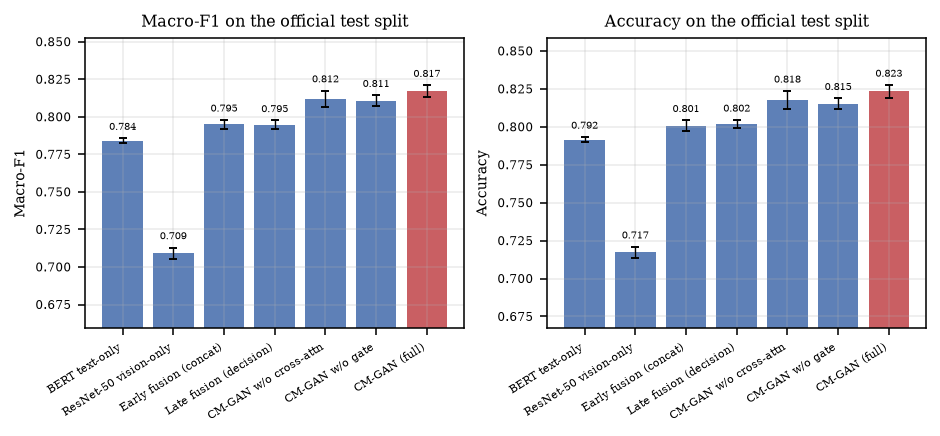

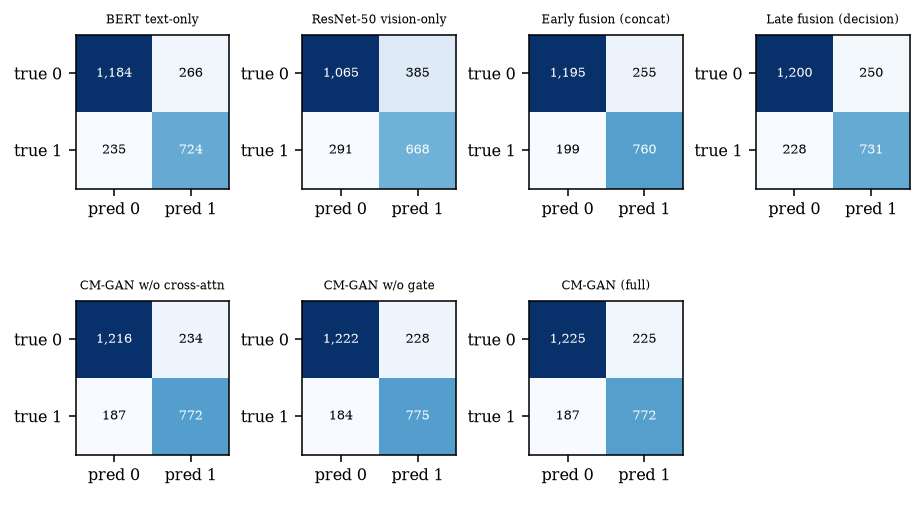

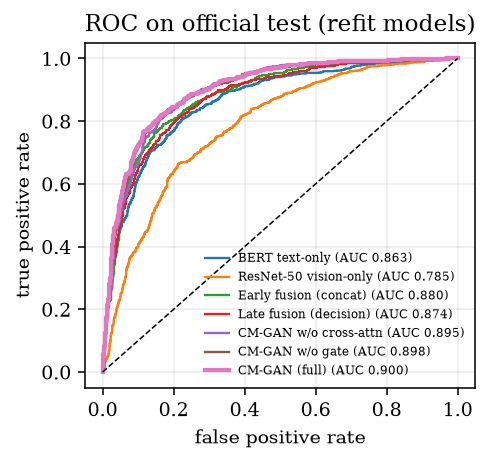

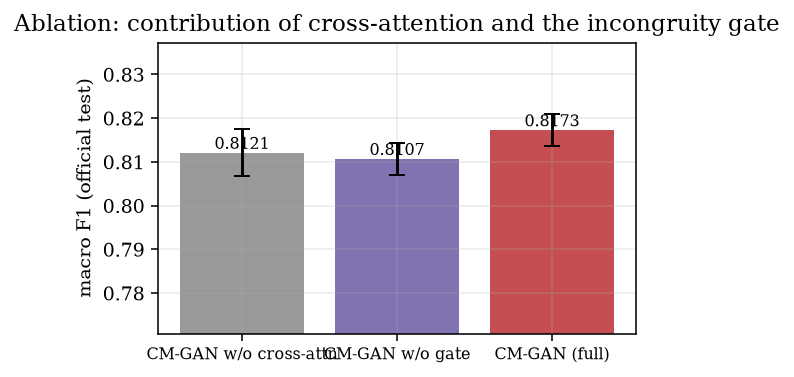

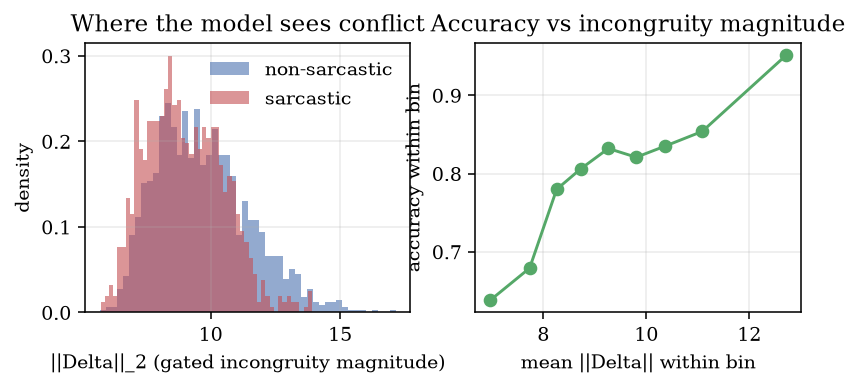

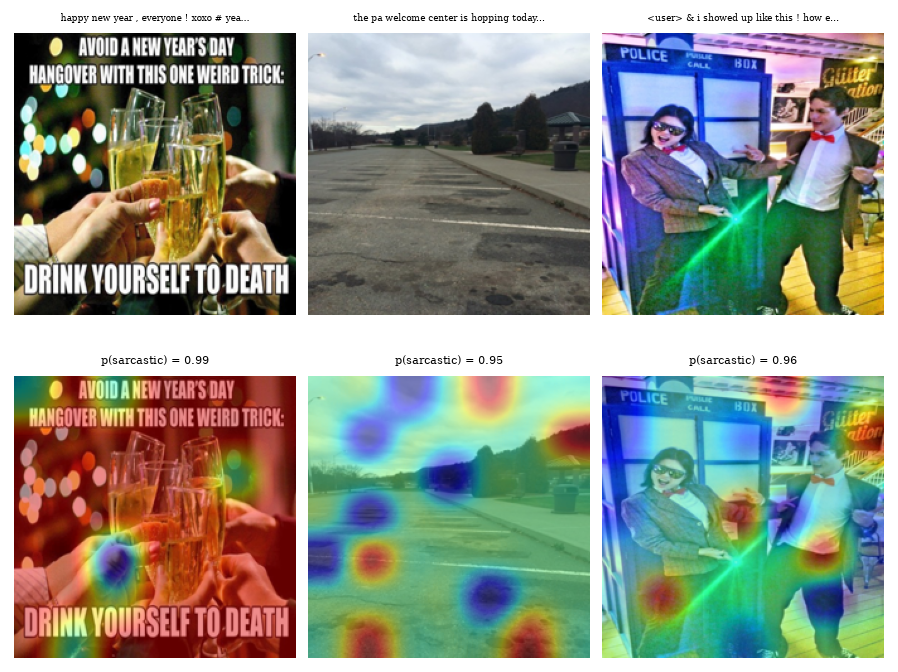

In [18]:
from IPython.display import Markdown, Image, display
display(Markdown(open('outputs/metrics/tables.md', encoding='utf-8').read()))
for f in ['fig10_metric_bars.png', 'fig11_confusion_matrices.png',
          'fig12_roc.png', 'fig14_ablation.png',
          'fig15_incongruity_magnitude.png', 'fig16_attention_maps.png']:
    display(Image(filename=f'outputs/figures/{f}', width=760))

## 9. Live inference

Six posts from the official test split that the model never saw during training, then one
arbitrary text + image pair. The same command prints the incongruity magnitude for each sample.

In [19]:
!python -m src.predict --examples 6

[23:08:29] vision standardisation from 4000 train rows (mean |x|=0.09)
caption                                              true           predicted           p  delta  ok   image
--------------------------------------------------------------------------------------------------------------------------------
well that 's right because women aren 't above no... sarcastic      sarcastic       0.947  10.30  Y   data\images\test\002380.jpg
nooo my name is just for show .  <user> <user> <u... sarcastic      sarcastic       0.933   8.23  Y   data\images\test\000121.jpg
need me a mans like this                             not sarcastic  not sarcastic   0.080   9.41  Y   data\images\test\001018.jpg
another night of " work " in long island for nlw ... not sarcastic  not sarcastic   0.015   9.36  Y   data\images\test\000983.jpg
dominic purcell no painel de prison break emoji_381  not sarcastic  not sarcastic   0.008   9.85  Y   data\images\test\000713.jpg
<user> great support effort on twitter ! 

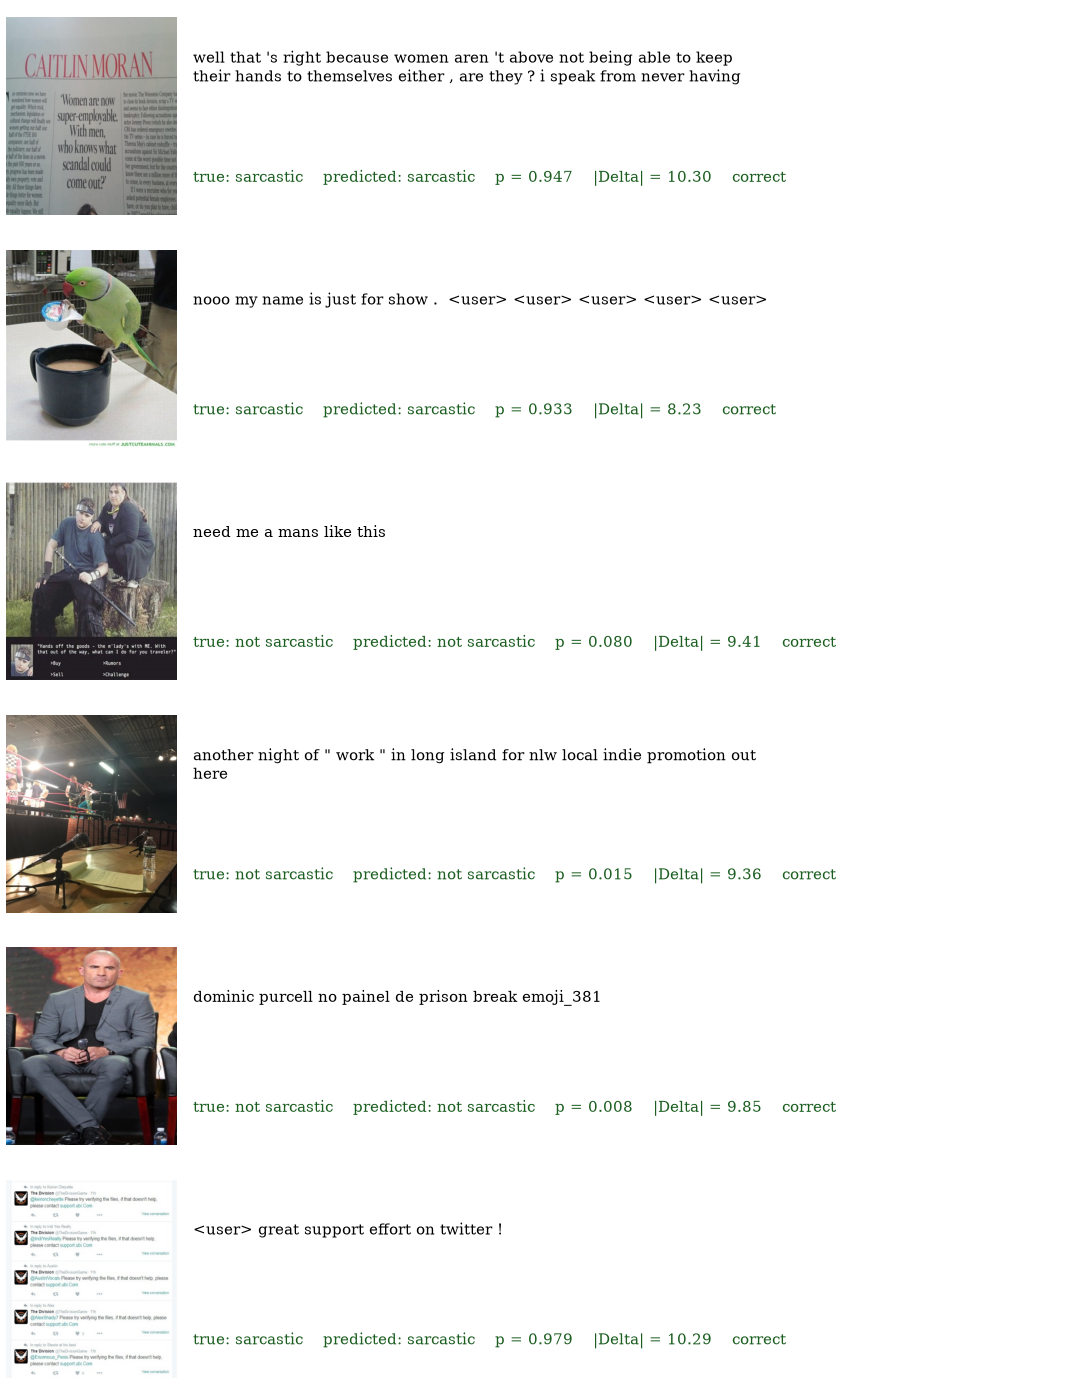

In [20]:
from IPython.display import Image, display
display(Image(filename='outputs/figures/predict_examples.png', width=760))

In [21]:
!python -m src.predict --text "great, another Monday at work" --image data/images/test/000000.jpg

[23:08:41] vision standardisation from 4000 train rows (mean |x|=0.09)
text       : great, another Monday at work
image      : data\images\test\000000.jpg
prediction : sarcastic  (p = 0.984, confidence 0.984)
divergence : |Delta| = 8.88  (higher means the two modalities disagree more)


## 10. Notes on reproducibility

* Every stage refuses to run if its inputs are missing, so a partial run fails loudly rather than
  quietly producing half a result.
* Feature extraction is cached; deleting `data/features/` forces a recompute (about 10 minutes).
* The 5-fold split is seeded (`SEED = 42` in `src/config.py`), so the folds are identical across runs.
* The mixed-precision training uses `torch.amp`, which is deterministic per seed but not bit-exact
  across GPU models; expect differences in the third decimal place on different hardware.
